# Heart Disease Diagnosis: Midterm Project (CSIS 260)

- **Goal:** predict whether a patient has heart disease (`1`) or not (`0`) from routine clinical measurements
- **Data:** 886 unique labeled patients (1,000 rows, 114 duplicate patients removed), 11 features (numeric, binary and categorical text)
- **Models:** Logistic Regression (linear), Random Forest (tree ensemble), KNN (instance-based)
- **Rules followed:** split before any fitting, leakage-free pipelines, fixed regularization, control model complexity to reduce overfitting, no hyperparameter search, no PCA
- **Most important metric:** recall on the disease class, because a missed sick patient (false negative) is costlier than a healthy patient being labeled sick (false positive)

# 1. Setup

## 1.1 Imports

- NumPy and pandas for data, Matplotlib and seaborn for plots
- scikit-learn for pipelines, models and metrics

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")

## 1.2 Settings

- Fixed seed `42` so every run gives the same split and results
- `TEST_SIZE = 0.30`: 70% train / 30% test split
- 5-fold stratified cross-validation, reused for every model so the comparison is fair

In [3]:
DATA_PATH = "dataset_heart_disease.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.30
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
CLASS_COLORS = {0: "#4C78A8", 1: "#E45756"}
MODEL_COLORS = {"Logistic Regression": "#4C78A8", "Random Forest": "#54A24B", "KNN": "#F58518"}
CLASS_NAMES = ["Normal", "Heart disease"]

# 2. Cleaning the Data

## 2.1 Load the data

- Read the CSV with pandas
- Check the shape and look at the first rows

In [4]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
display(df.head())

Shape (rows, columns): (1000, 13)


,patient id,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,heart disease
0,1,40,Male,Atypical Angina,140,289,0,Normal,172,No,0.0,Upsloping,0
1,2,49,Female,Non-Anginal Pain,160,180,0,Normal,156,No,1.0,Flat,1
2,3,37,Male,Atypical Angina,130,283,0,ST-T Abnormality,98,No,0.0,Upsloping,0
3,4,48,Female,Asymptomatic,138,214,0,Normal,108,Yes,1.5,Flat,1
4,5,54,Male,Non-Anginal Pain,150,195,0,Normal,122,No,0.0,Upsloping,0


## 2.2 Inspect structure and quality

- inspect the dataset to identify potential data-quality problems
- Data types per column (text vs numeric)
- Summary statistics of every numeric column
- Missing values and duplicate rows

In [5]:
df.info()
print()
display(df.describe().T.round(2))
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient id           1000 non-null   int64  
 1   age                  1000 non-null   int64  
 2   sex                  1000 non-null   str    
 3   chest pain type      1000 non-null   str    
 4   resting bp s         1000 non-null   int64  
 5   cholesterol          1000 non-null   int64  
 6   fasting blood sugar  1000 non-null   int64  
 7   resting ecg          1000 non-null   str    
 8   max heart rate       1000 non-null   int64  
 9   exercise angina      1000 non-null   str    
 10  oldpeak              1000 non-null   float64
 11  ST slope             999 non-null    str    
 12  heart disease        1000 non-null   int64  
dtypes: float64(1), int64(7), str(5)
memory usage: 101.7 KB



,count,mean,std,min,25%,50%,75%,max
patient id,1000.0,500.50,288.82,1.0,250.75,500.5,750.25,1000.0
age,1000.0,53.60,9.34,28.0,47.00,54.0,60.00,77.0
resting bp s,1000.0,132.27,18.29,0.0,120.00,130.0,140.00,200.0
cholesterol,1000.0,203.37,106.74,0.0,179.75,226.0,268.00,603.0
fasting blood sugar,1000.0,0.22,0.42,0.0,0.00,0.0,0.00,1.0
max heart rate,1000.0,138.18,25.45,60.0,120.00,140.0,158.00,202.0
oldpeak,1000.0,0.92,1.07,-2.6,0.00,0.6,1.50,6.2
heart disease,1000.0,0.54,0.50,0.0,0.00,1.0,1.00,1.0


Missing values per column:
patient id             0
age                    0
sex                    0
chest pain type        0
resting bp s           0
cholesterol            0
fasting blood sugar    0
resting ecg            0
max heart rate         0
exercise angina        0
oldpeak                0
ST slope               1
heart disease          0

Duplicate rows: 0


## 2.3 Drop the identifier

- `patient id` is only a label with no medical meaning, so it is removed
- Keeping it could let a model memorize patients instead of learning patterns
- **Duplicates:** without the ID, 114 patients appear twice with identical values (the same patient entered twice under two IDs). The check in section 2.2 showed 0 only because every row had a different ID
- The copies are removed so no patient can end up in both the training and the test set: 886 unique patients remain

In [6]:
df = df.drop(columns="patient id")
print("Columns now:", list(df.columns))

# duplicates are only visible once the ID is gone
print("Duplicate rows (ignoring the ID):", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Columns now: ['age', 'sex', 'chest pain type', 'resting bp s', 'cholesterol', 'fasting blood sugar', 'resting ecg', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope', 'heart disease']
Duplicate rows (ignoring the ID): 114
Shape after removing duplicates: (886, 12)


## 2.4 Detect physiologically invalid values

- check for medically impossible or suspicious numerical values
- Cholesterol and resting blood pressure can never be 0 in a living patient (min for both in **section 2.2** is 0)
- Oldpeak (ST depression) can be negative in real data, so negatives are checked but not treated as errors
- Cholesterol above 400 mg/dl is rare but possible
- Check how the target relates to the invalid cholesterol rows

In [7]:
print("Cholesterol == 0      :", (df["cholesterol"] == 0).sum())
print("Resting bp == 0       :", (df["resting bp s"] == 0).sum())
print("Oldpeak < 0           :", (df["oldpeak"] < 0).sum())
print("Cholesterol > 400     :", (df["cholesterol"] > 400).sum())
print("Max heart rate range  :", df["max heart rate"].min(), "to", df["max heart rate"].max(), "(documented 60 to 202)")
print("\nHeart disease rate when cholesterol is 0 vs not:")
display(df.groupby(df["cholesterol"] == 0)["heart disease"].agg(patients="count", disease_rate="mean").round(3))

Cholesterol == 0      : 172
Resting bp == 0       : 1
Oldpeak < 0           : 13
Cholesterol > 400     : 13
Max heart rate range  : 60 to 202 (documented 60 to 202)

Heart disease rate when cholesterol is 0 vs not:


,patients,disease_rate
cholesterol,,
False,714,0.472
True,172,0.884


## 2.5 Fix invalid values

- Cholesterol of 0 is not random: most of those patients have heart disease, so dropping them would remove a large group of sick patients
- Add a flag column `chol_missing` (1 = cholesterol was not measured) so the model can use that pattern
- Turn the impossible zeros (cholesterol and blood pressure) into missing values (`NaN`)
- The actual filling with the median happens later inside the pipeline, fitted on the training data only (no leakage)

In [8]:
df["chol_missing"] = (df["cholesterol"] == 0).astype(int)
df["cholesterol"] = df["cholesterol"].replace(0, np.nan)
df["resting bp s"] = df["resting bp s"].replace(0, np.nan)

print("Missing values after marking invalid zeros:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("chol_missing flag count:", df["chol_missing"].sum())

Missing values after marking invalid zeros:
resting bp s      1
cholesterol     172
ST slope          1
chol_missing flag count: 172


## 2.6 Check outliers

- Count values outside 1.5 x IQR for each numeric feature
- Rule: IQR = Q3 - Q1 --> remove upper and lower 25% of data (outliers)
- Decision: keep them. They are plausible clinical values, not errors, and tree models and scaling handle them

In [9]:
numeric_check = ["age", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]
rows = []
for c in numeric_check:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": c, "lower bound": round(low, 1), "upper bound": round(high, 1),
                 "outliers": int(((df[c] < low) | (df[c] > high)).sum())})
display(pd.DataFrame(rows).set_index("feature"))

,lower bound,upper bound,outliers
feature,,,
age,27.5,79.5,0
resting bp s,90.0,170.0,27
cholesterol,106.0,378.0,23
max heart rate,65.0,209.0,2
oldpeak,-2.2,3.8,14


## 2.7 Check categorical columns

- Look at every category and its count/frequency
- Confirms spelling is consistent and shows the one missing `ST slope` value (handled in the pipeline)

In [10]:
for c in ["sex", "chest pain type", "resting ecg", "exercise angina", "ST slope", "fasting blood sugar"]:
    print(df[c].value_counts(dropna=False).to_string(), "\n")

sex
Male      702
Female    184 

chest pain type
Asymptomatic        481
Non-Anginal Pain    197
Atypical Angina     165
Typical Angina       43 

resting ecg
Normal              532
LVH                 178
ST-T Abnormality    176 

exercise angina
No     525
Yes    361 

ST slope
Flat           441
Upsloping      384
Downsloping     60
NaN              1 

fasting blood sugar
0    677
1    209 



# 3. Visualization and Splitting the Data

## 3.1 Split first: 70% train / 30% test

- `stratify=y` keeps the same disease proportion in both parts of the split
- 70% of the patients (620) are used for training and 30% (266) for the final test
- important to ensure a fair evaluation of the model

In [11]:
X = df.drop(columns="heart disease")
y = df["heart disease"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Disease rate -> train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

train_df = X_train.assign(**{"heart disease": y_train})

Train: (620, 12) | Test: (266, 12)
Disease rate -> train: 0.552 | test: 0.553


- Disease rate in both training and test set is the same -> stratified split worked -> test is fair

## 3.2 Class balance

- Check distribution of both parts of the split to ensure it is stratified
- Bar chart of how many normal and heart disease patients are in each part
- Roughly balanced classes mean accuracy is a fair metric, with recall and F1 still reported

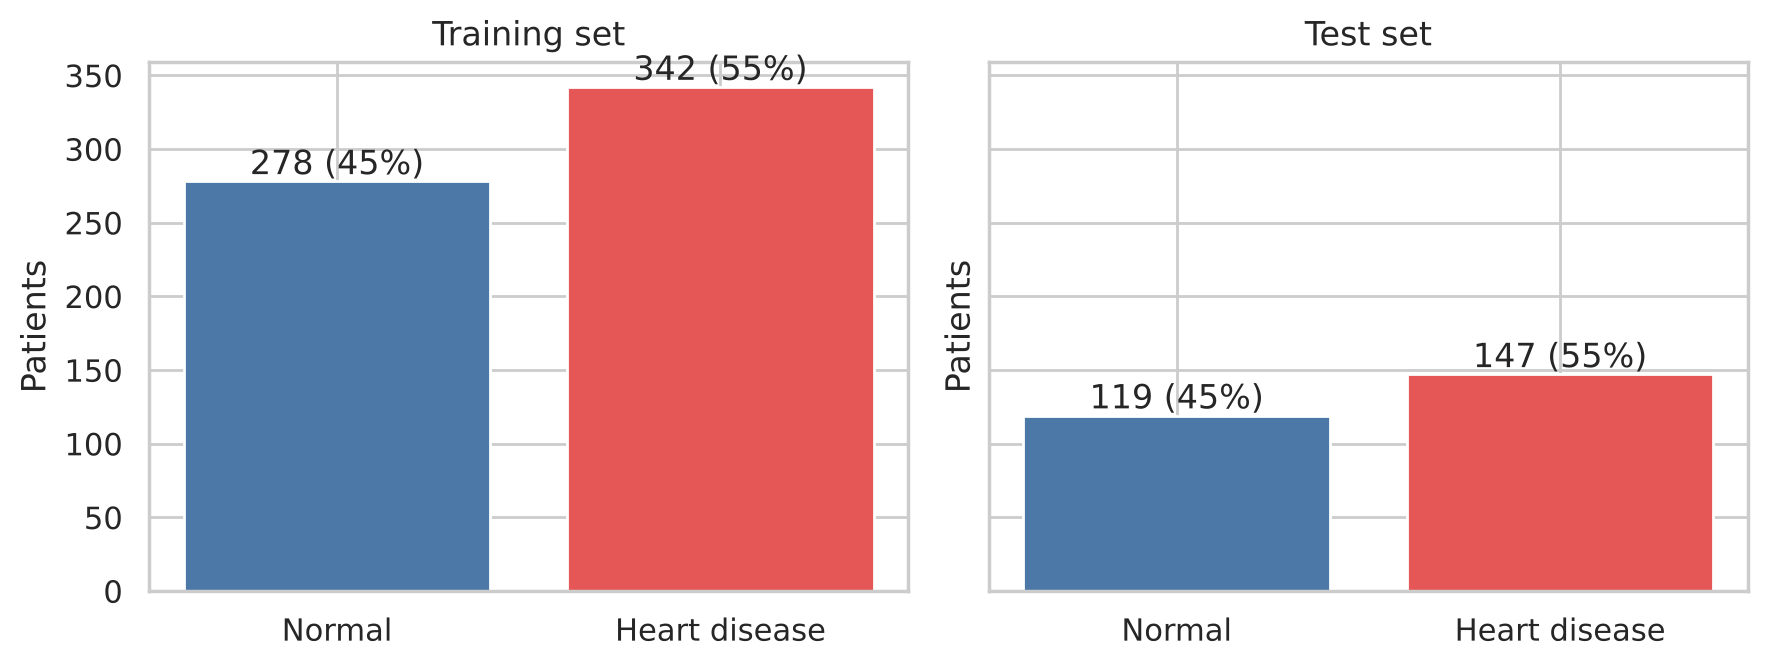

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, (title, s) in zip(axes, [("Training set", y_train), ("Test set", y_test)]):
    counts = s.value_counts().sort_index()
    bars = ax.bar(CLASS_NAMES, counts.values, color=[CLASS_COLORS[0], CLASS_COLORS[1]])
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 5, f"{v} ({v / len(s):.0%})", ha="center")
    ax.set_title(title)
    ax.set_ylabel("Patients")
plt.tight_layout()
plt.show()

## 3.3 Statistical summaries

- Summary statistics of the numeric features in the training set
- Mean of each feature for normal vs heart disease patients, to see which ones differ
- Compare the mean feature values between normal patients and patients with heart disease
- Values suggest that some numerical features may be more useful than others for predicting the diagnosis

In [13]:
numeric_cols = ["age", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]
display(train_df[numeric_cols].describe().T.round(2))
print("Mean per class:")
display(train_df.groupby("heart disease")[numeric_cols].mean().T.round(2).rename(columns={0: "Normal", 1: "Heart disease"}))

,count,mean,std,min,25%,50%,75%,max
age,620.0,53.94,9.56,29.0,47.0,55.0,61.00,77.0
resting bp s,620.0,132.35,18.58,92.0,120.0,130.0,140.00,200.0
cholesterol,506.0,247.71,59.70,85.0,211.0,241.0,279.75,603.0
max heart rate,620.0,135.89,25.71,63.0,118.0,137.0,155.00,202.0
oldpeak,620.0,0.86,1.05,-2.6,0.0,0.6,1.50,5.6


Mean per class:


heart disease,Normal,Heart disease
age,51.15,56.20
resting bp s,130.21,134.10
cholesterol,241.88,254.18
max heart rate,147.36,126.57
oldpeak,0.43,1.21


## 3.4 Histograms of numeric features

- Shows the distribution shape and where the two classes separate

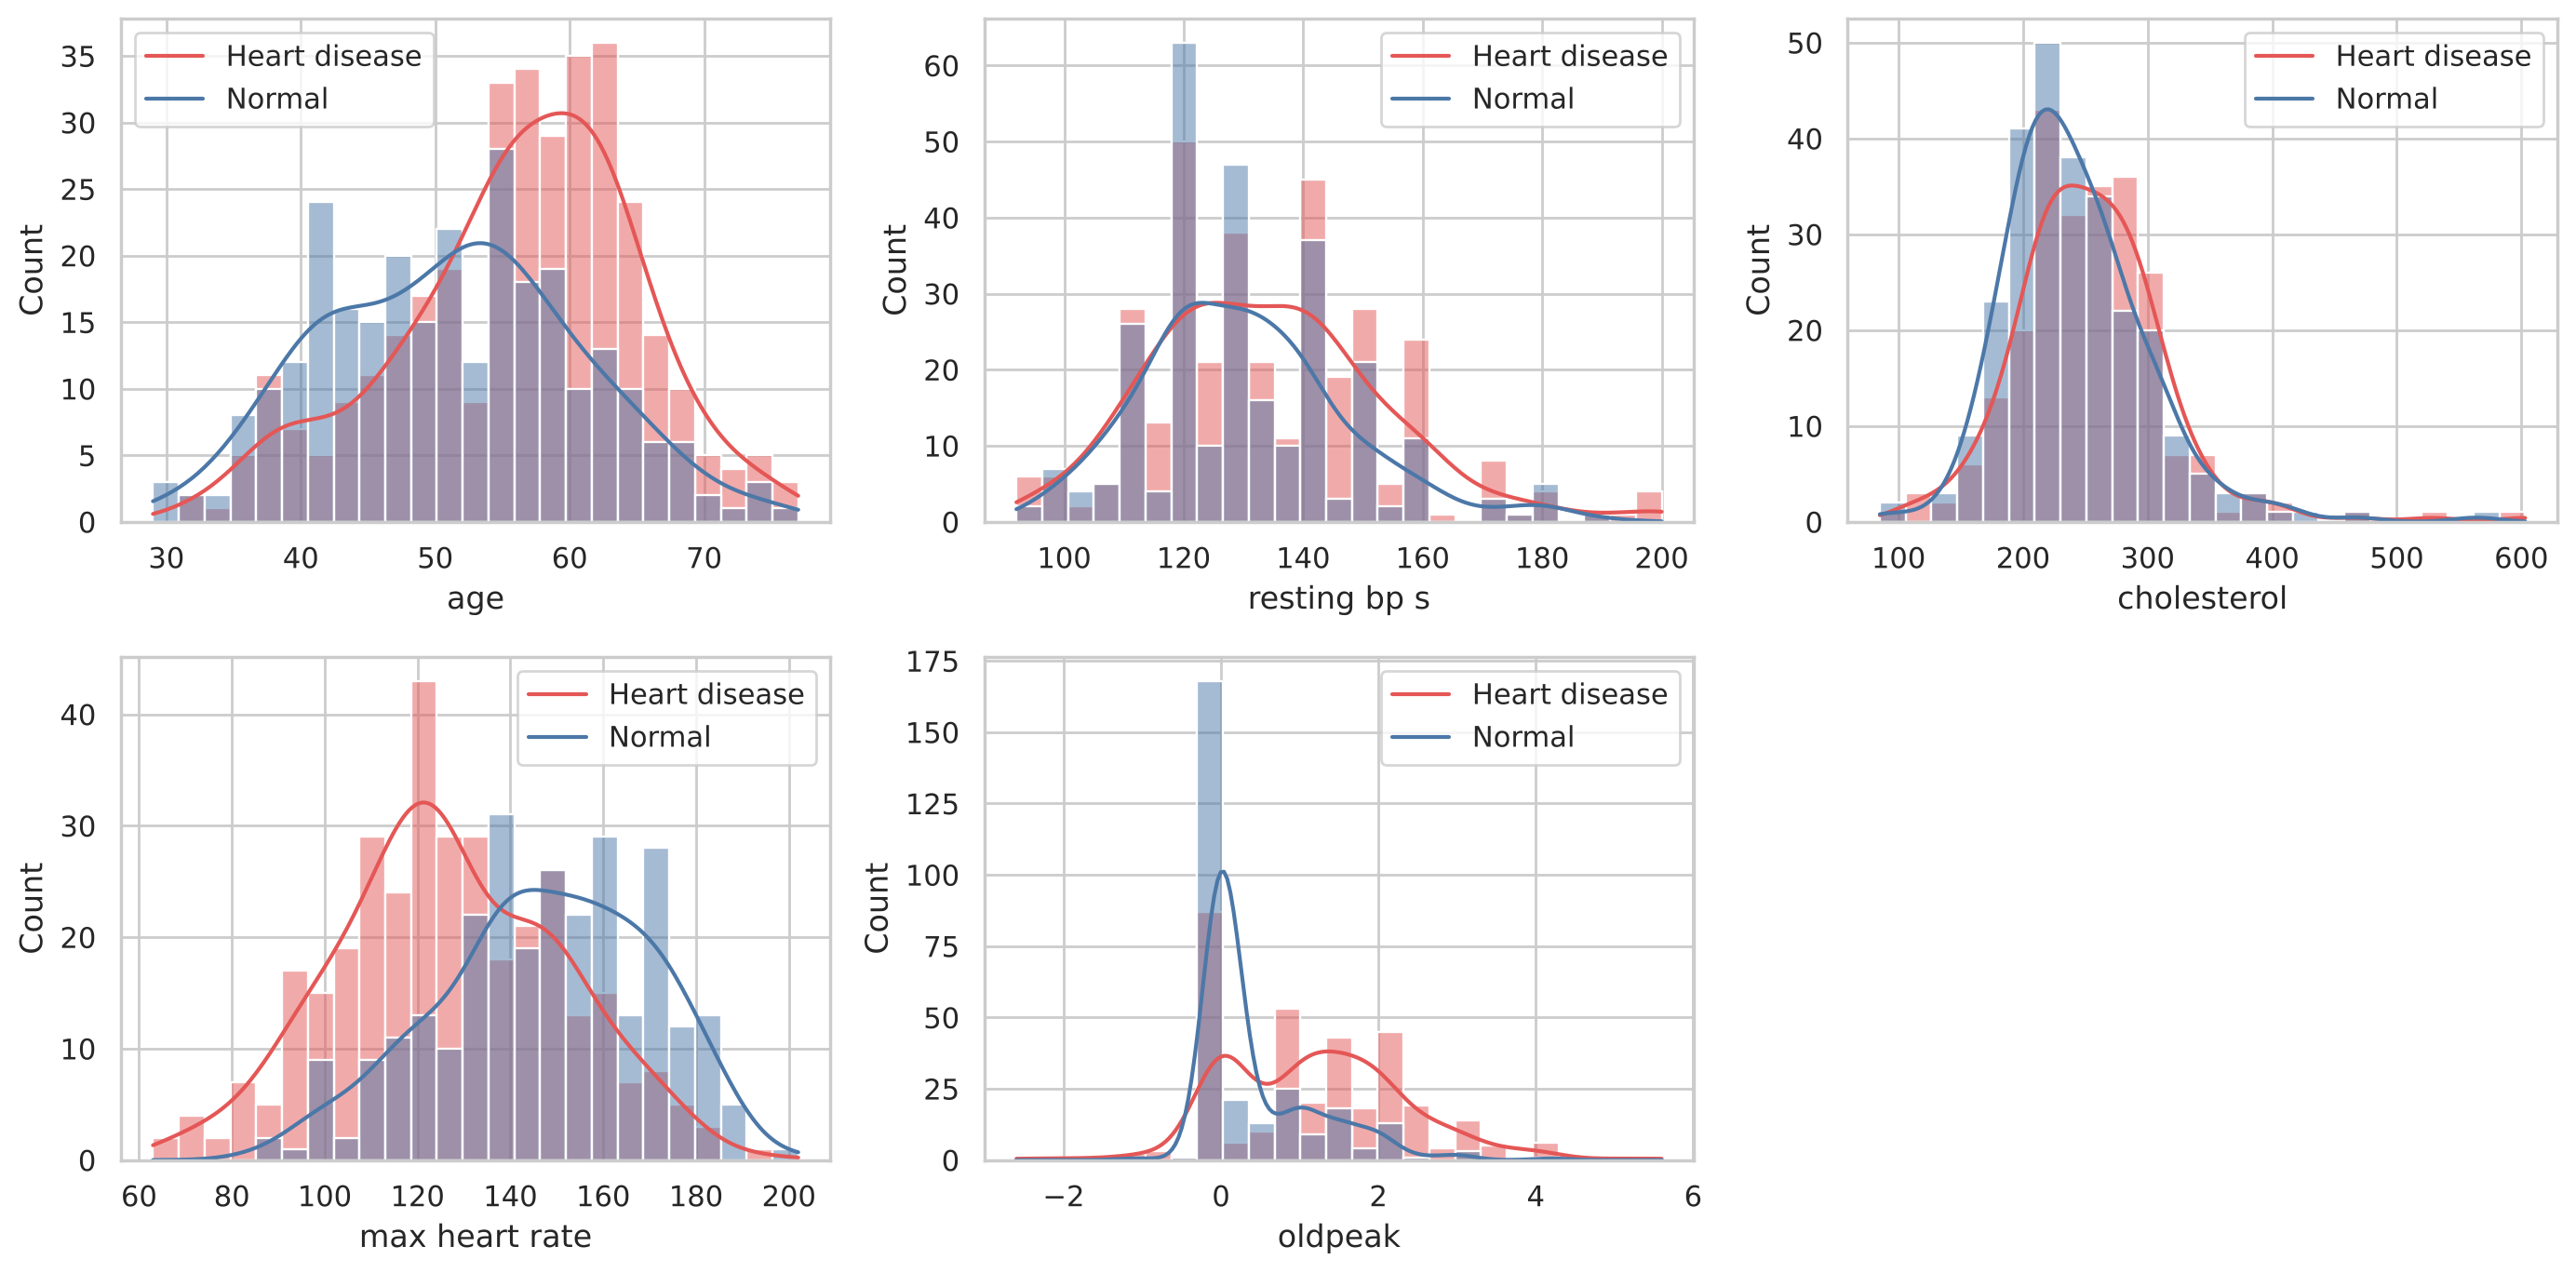

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, numeric_cols):
    sns.histplot(data=train_df, x=c, hue="heart disease", bins=25, kde=True,
                 palette=CLASS_COLORS, ax=ax, stat="count", common_norm=False)
    #ax.set_title(c)
    ax.legend(title="", labels=["Heart disease", "Normal"])
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## 3.5 Box plots of numeric features

- Compare each feature between the two classes
- Shows the median, quartiles, spread, and outliers
- Dots outside the whiskers are the outliers counted in section 2.6

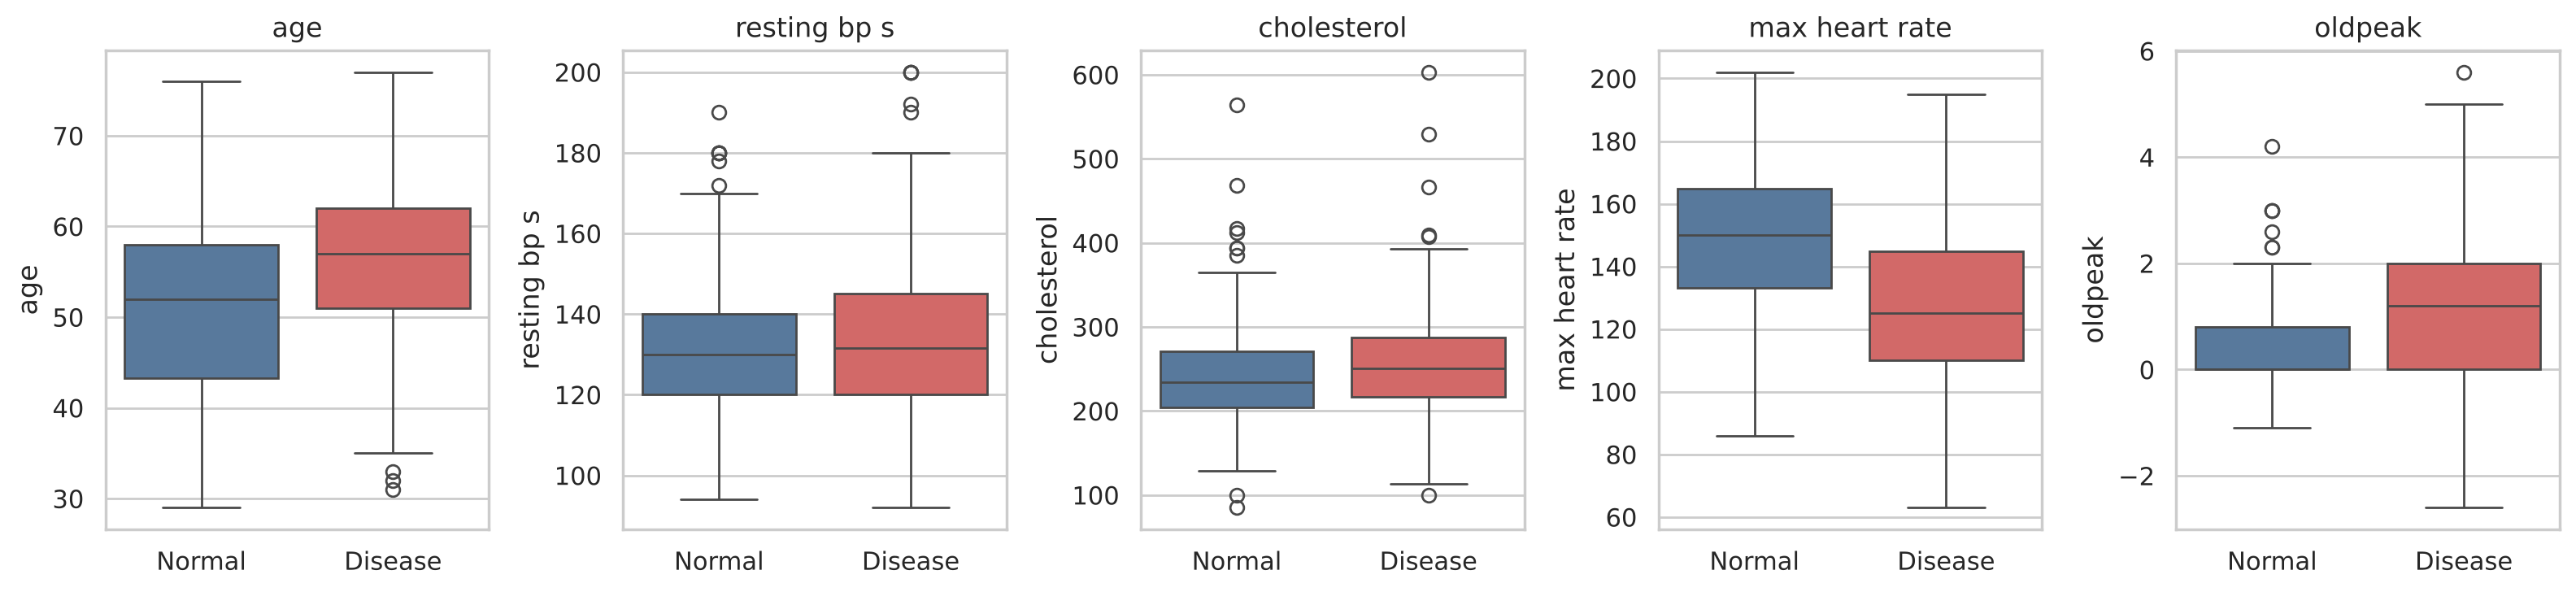

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, c in zip(axes, numeric_cols):
    sns.boxplot(data=train_df, x="heart disease", y=c, hue="heart disease", palette=CLASS_COLORS,
                dodge=False, legend=False, ax=ax)
    ax.set_xticklabels(["Normal", "Disease"])
    ax.set_xlabel("")
    ax.set_title(c)
plt.tight_layout()
plt.show()

## 3.6 Categorical features vs disease rate

- Investigate the relationship between categorical features and heart disease
- Calculate the proportion of patients with heart disease within each category (n = number of patients) in the training set
- Includes the `chol_missing` flag created in section 2.5

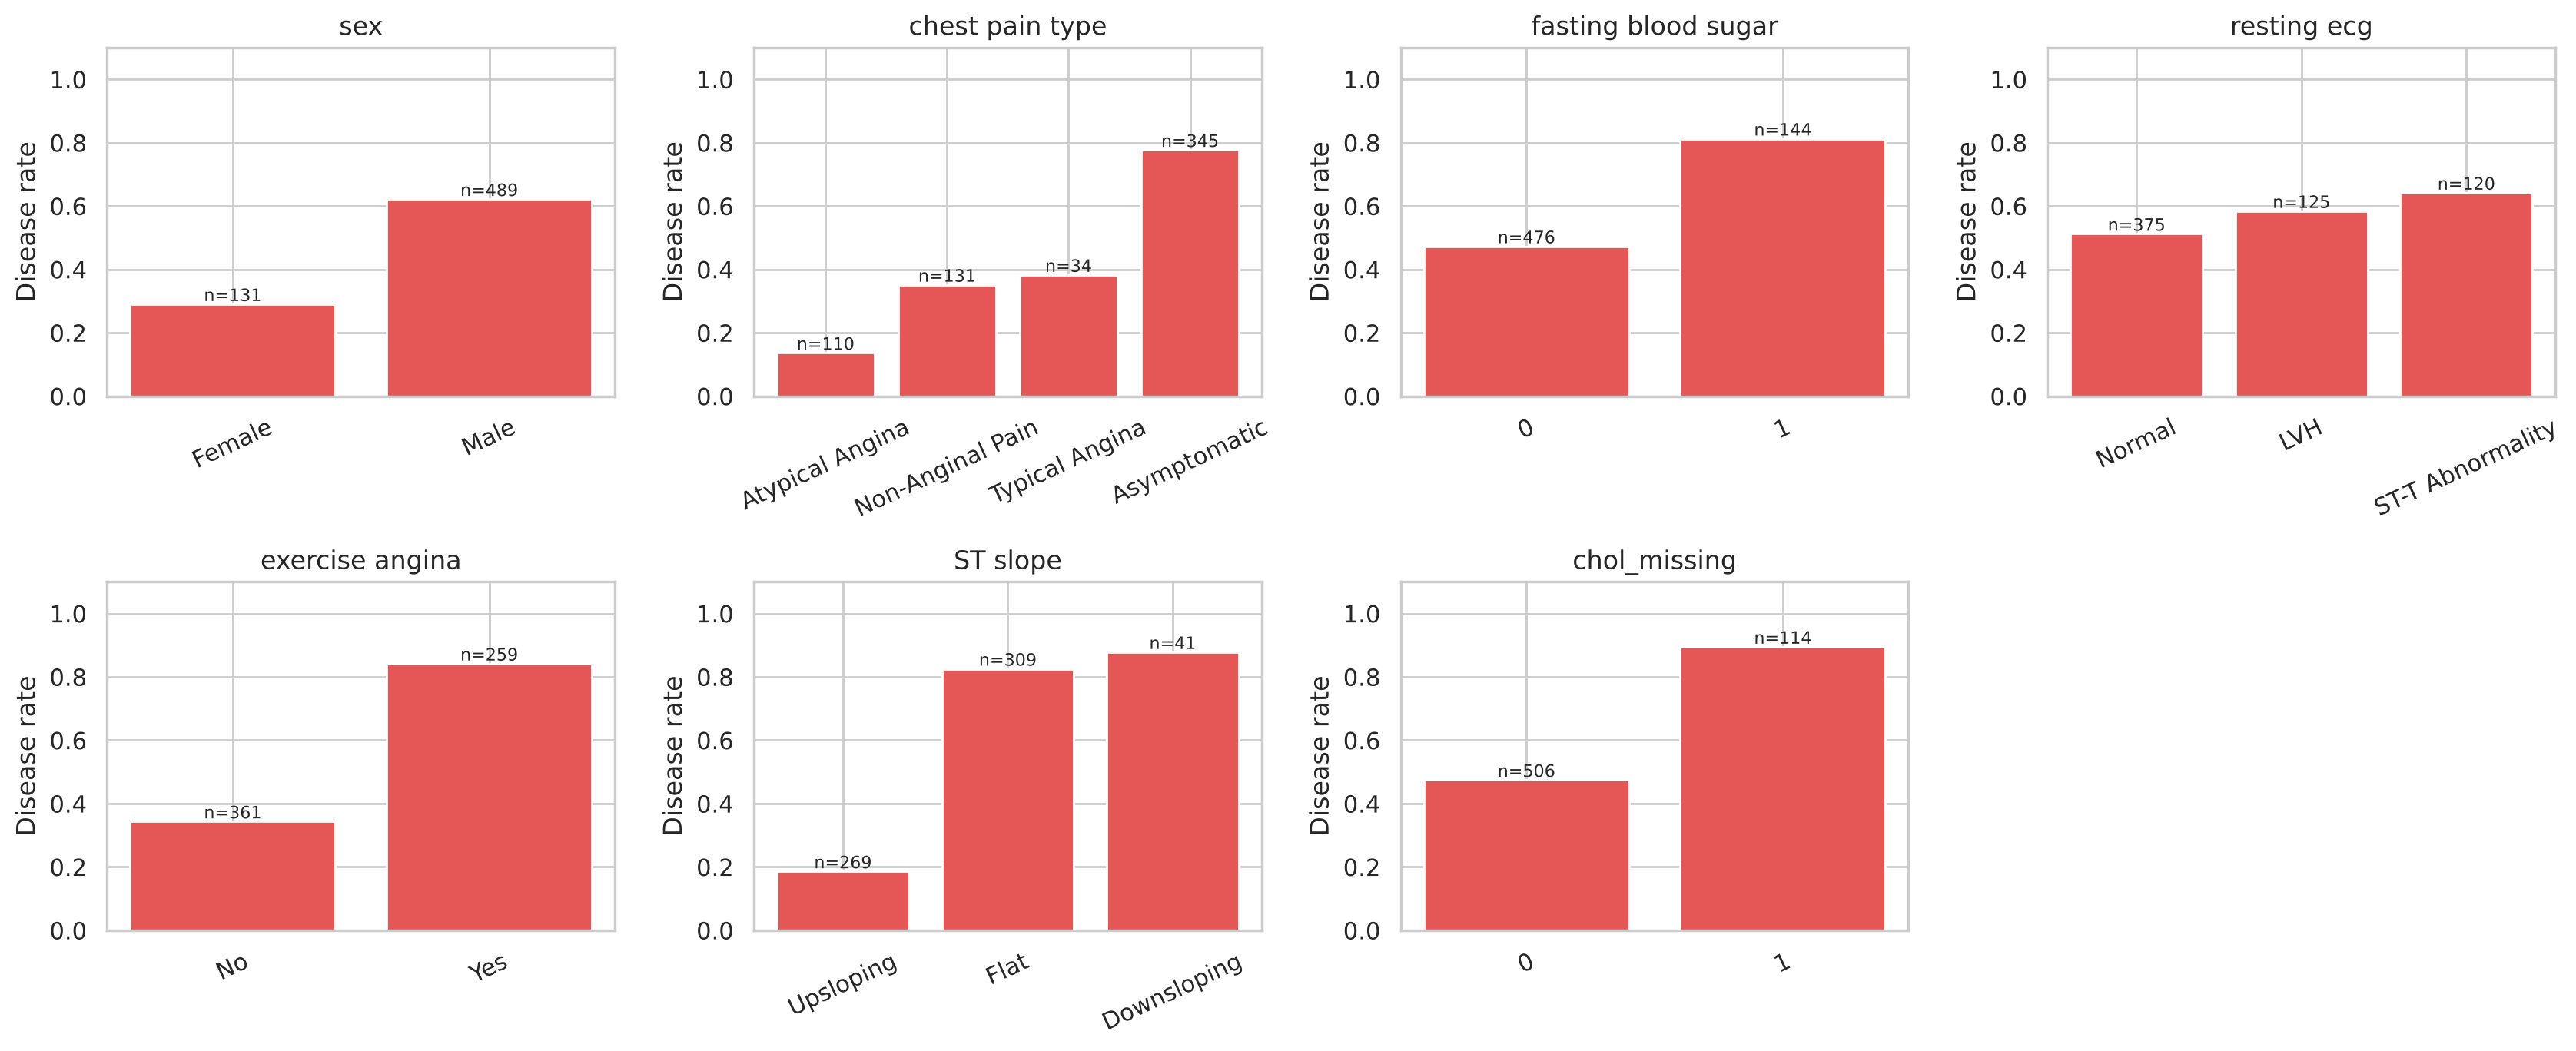

In [16]:
cat_cols = ["sex", "chest pain type", "fasting blood sugar", "resting ecg",
            "exercise angina", "ST slope", "chol_missing"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.flat, cat_cols):
    g = train_df.groupby(c)["heart disease"].agg(["mean", "count"]).sort_values("mean")
    bars = ax.bar(g.index.astype(str), g["mean"], color="#E45756")
    for b, n in zip(bars, g["count"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"n={n}", ha="center", fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(c)
    ax.set_ylabel("Disease rate")
    ax.tick_params(axis="x", rotation=25)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## 3.7 Correlation heatmap

- Categories are converted to numbers only for this plot (binary to 0/1, `ST slope` to 0 = up (normal) / 1 = flat / 2 = down, other categories to dummy columns)
- Shows how features relate to each other and to the target `heart disease`
- Heatmap helped us identify relationships between the clinical features and the target variable

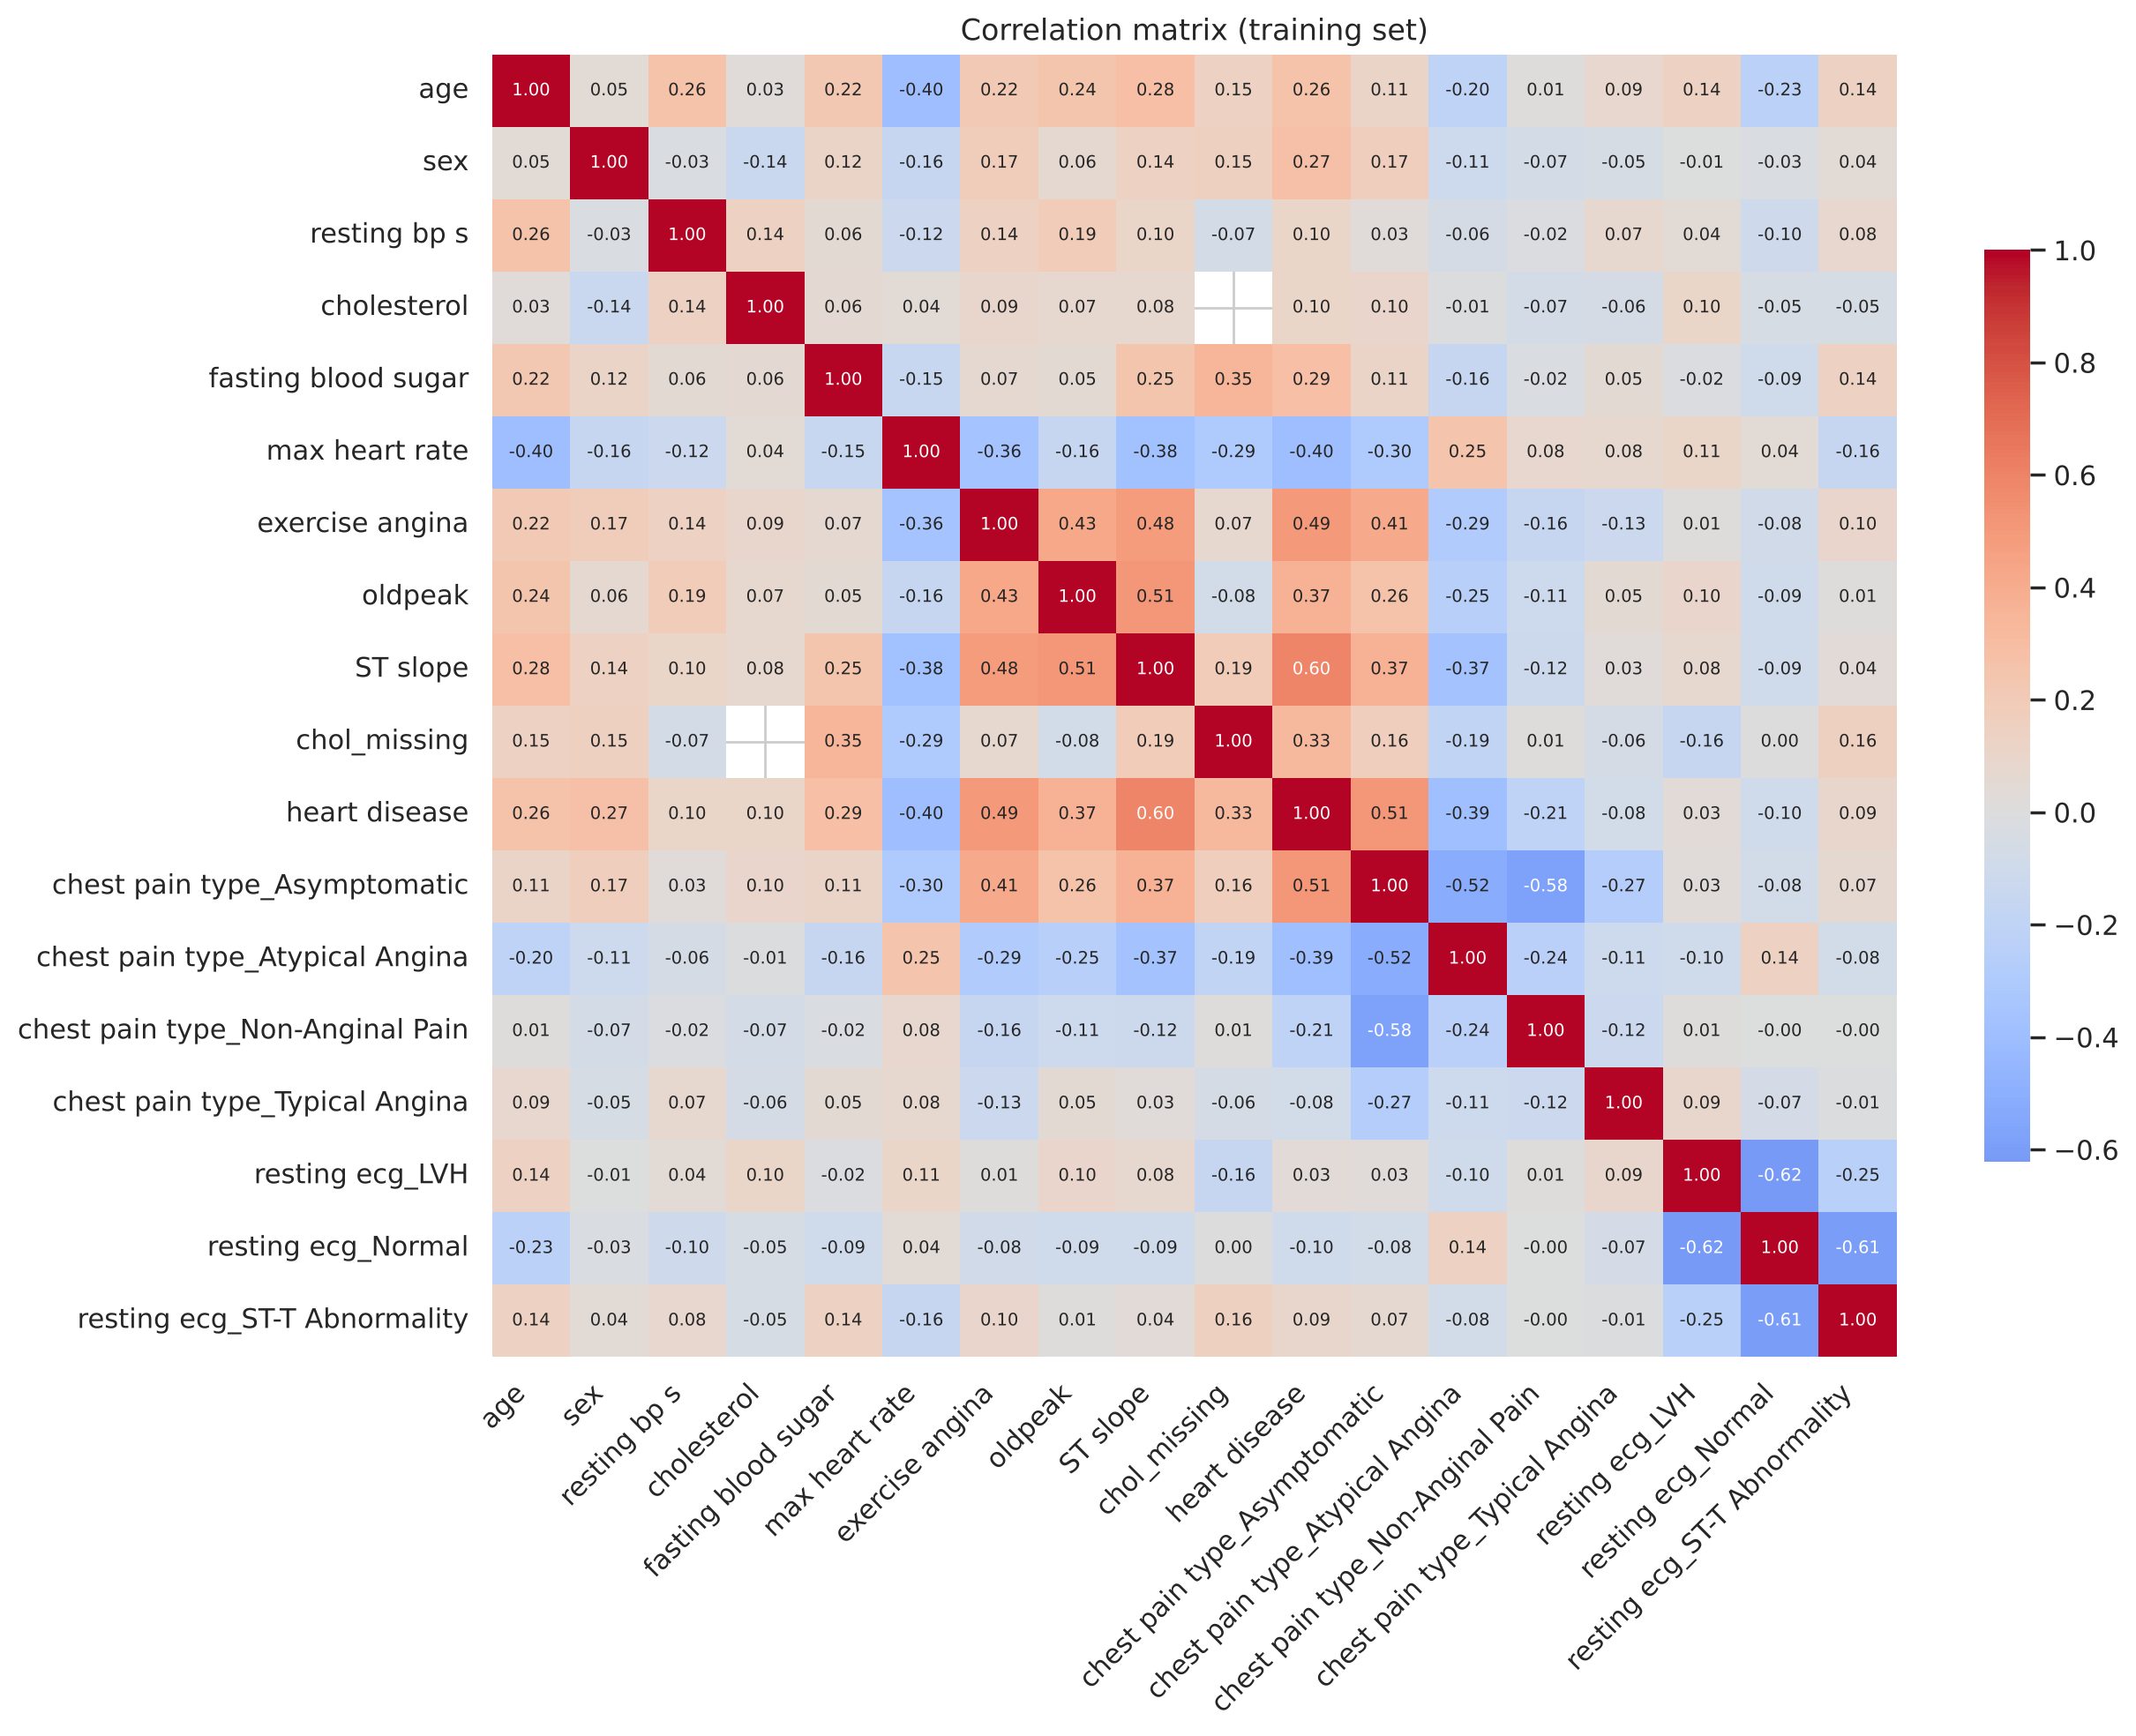

In [17]:
enc = train_df.copy()
enc["sex"] = (enc["sex"] == "Male").astype(int)
enc["exercise angina"] = (enc["exercise angina"] == "Yes").astype(int)
enc["ST slope"] = enc["ST slope"].map({"Upsloping": 0, "Flat": 1, "Downsloping": 2})
enc = pd.get_dummies(enc, columns=["chest pain type", "resting ecg"]).astype(float)
corr = enc.corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (training set)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

- Some features partly overlap, mainly the exercise-test ones: oldpeak and ST slope (0.51), exercise angina and ST slope (0.48), and exercise angina with oldpeak (0.43). No pair goes above about 0.5, so each feature still adds its own information and PCA isn’t needed.

## 3.8 Correlation with the target

- Features ranked by their correlation with `heart disease`
- Red = as the feature goes up, heart disease goes up
- Blue = as the feature goes up, heart disease goes down (opposite correlation)

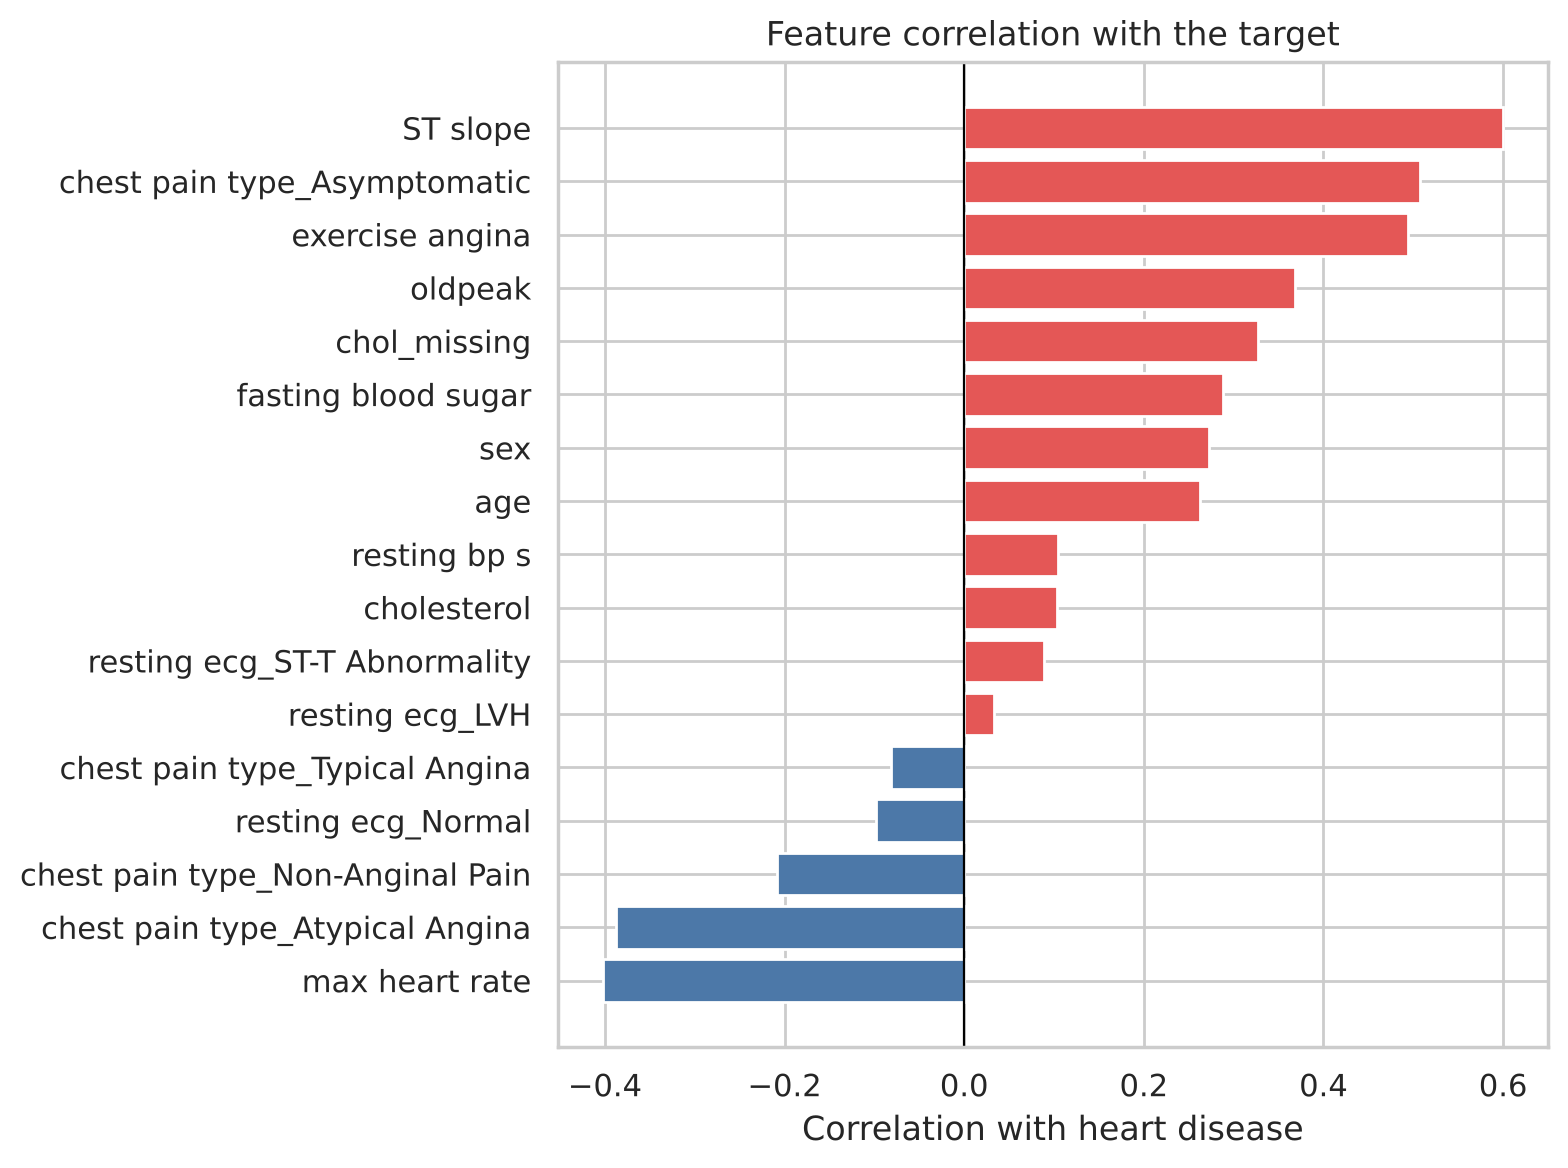

In [18]:
target_corr = corr["heart disease"].drop("heart disease").sort_values()
plt.figure(figsize=(8, 6))
plt.barh(target_corr.index, target_corr.values,
         color=["#E45756" if v > 0 else "#4C78A8" for v in target_corr.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with heart disease")
plt.title("Feature correlation with the target")
plt.tight_layout()
plt.show()

## 3.9 EDA insights

- **Classes are balanced:** about 55% heart disease and 45% normal in both train and test, so accuracy is a fair metric (recall and F1 are still reported)
- **Differences between the classes (mean, normal vs disease):** max heart rate 147 vs 127 (lower in disease), oldpeak 0.43 vs 1.21 (higher in disease), age 51 vs 56 (older in disease). Cholesterol (242 vs 254) and resting blood pressure (130 vs 134) differ only a little
- **Strongest correlations with the target:** `ST slope` 0.60, asymptomatic chest pain 0.51, exercise angina 0.49, max heart rate -0.40, atypical angina -0.39, oldpeak 0.37, `chol_missing` 0.33, male sex 0.27. Cholesterol value (0.10) and resting ECG (0.10 or less) are only weakly related to the target
- **Features partly overlap, but not enough to need PCA:** oldpeak and `ST slope` (0.51), exercise angina and `ST slope` (0.48), exercise angina and oldpeak (0.43). The two blank cells in the heatmap are cholesterol vs `chol_missing`: the correlation is undefined because cholesterol is missing in every row where the flag is 1
- **Missing cholesterol is not random:** 172 of the 886 patients (19%) had cholesterol recorded as 0, and 88% of them (152) have heart disease, against 47% of the other patients. This is why the flag column `chol_missing` was added
- **Chest pain type and ST slope separate the classes sharply:** 79% of asymptomatic patients (no chest pain symptoms) have heart disease vs 13% of atypical angina patients, and 83% of patients with a flat ST slope vs 19% with an upsloping one (rates on all 886 patients)
- **Outliers:** a few cholesterol values above 400 (up to 603) and oldpeak up to 6.2. They are plausible clinical values, so they were kept

## 3.10 Preprocessing pipeline

- Built using scikit-learn `ColumnTransformer`, so every step is fitted on training data only and then applied to the test data
- Each feature type is handled differently: numeric, binary/nominal, ordinal, already 0/1
- **Numeric:** fill missing values with the median, then standardize (scaling is skipped for Random Forest, which does not need it)
- **Binary / nominal categories** (`sex`, `exercise angina`, `chest pain type`, `resting ecg`): one-hot encoding (binary ones become a single 0/1 column)
- **Ordinal category** (`ST slope`): Upsloping < Flat < Downsloping, encoded as 0/1/2 because the order reflects increasing severity. The one missing value is filled with the most frequent category
- **Already 0/1:** `fasting blood sugar` and `chol_missing` pass through unchanged
- A pipeline allows separate fitting inside each cross-validation training fold

In [19]:
numeric_cols = ["age", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]
onehot_cols = ["sex", "exercise angina", "chest pain type", "resting ecg"]
ordinal_cols = ["ST slope"]
passthrough_cols = ["fasting blood sugar", "chol_missing"]

def make_preprocessor(scale=True, drop=()):
    keep = lambda cols: [c for c in cols if c not in drop]
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    parts = [
        ("num", Pipeline(num_steps), keep(numeric_cols)),
        ("onehot", OneHotEncoder(drop="if_binary"), keep(onehot_cols)),
        ("pass", "passthrough", keep(passthrough_cols)),
    ]
    if keep(ordinal_cols):
        parts.append(("ordinal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(categories=[["Upsloping", "Flat", "Downsloping"]]))]),
            keep(ordinal_cols)))
    return ColumnTransformer(parts)

## 3.11 Check the pipeline for leakage

- Fit the scaler on the training data only, then transform both parts
- Training means are exactly 0 and standard deviations 1
- The test set is close but not exact, which proves the test data did not influence the scaler
- No missing values remain after the pipeline

In [20]:
prep_demo = make_preprocessor(scale=True).fit(X_train)
Xt_train, Xt_test = prep_demo.transform(X_train), prep_demo.transform(X_test)
names = [n.split("__", 1)[1] for n in prep_demo.get_feature_names_out()]

print("Features after encoding:", Xt_train.shape[1])
print(names)
scaled = pd.DataFrame({"train mean": Xt_train[:, :5].mean(axis=0), "test mean": Xt_test[:, :5].mean(axis=0),
                       "train std": Xt_train[:, :5].std(axis=0), "test std": Xt_test[:, :5].std(axis=0)},
                      index=numeric_cols).round(3)
display(scaled)
print("Missing values left (train/test):", np.isnan(Xt_train).sum(), "/", np.isnan(Xt_test).sum())

Features after encoding: 17
['age', 'resting bp s', 'cholesterol', 'max heart rate', 'oldpeak', 'sex_Male', 'exercise angina_Yes', 'chest pain type_Asymptomatic', 'chest pain type_Atypical Angina', 'chest pain type_Non-Anginal Pain', 'chest pain type_Typical Angina', 'resting ecg_LVH', 'resting ecg_Normal', 'resting ecg_ST-T Abnormality', 'fasting blood sugar', 'chol_missing', 'ST slope']


,train mean,test mean,train std,test std
age,-0.0,-0.162,1.0,0.957
resting bp s,0.0,0.019,1.0,0.907
cholesterol,0.0,-0.108,1.0,0.961
max heart rate,-0.0,0.057,1.0,0.974
oldpeak,-0.0,0.064,1.0,1.014


Missing values left (train/test): 0 / 0


## 3.12 Feature selection: relevance ranking

- Investigate which features were the most relevant for predicting heart disease
- Filter method: mutual information between each feature and the target, computed on the training set only
- Higher means the feature tells us more about heart disease
- Features below 0.01 are candidates to remove

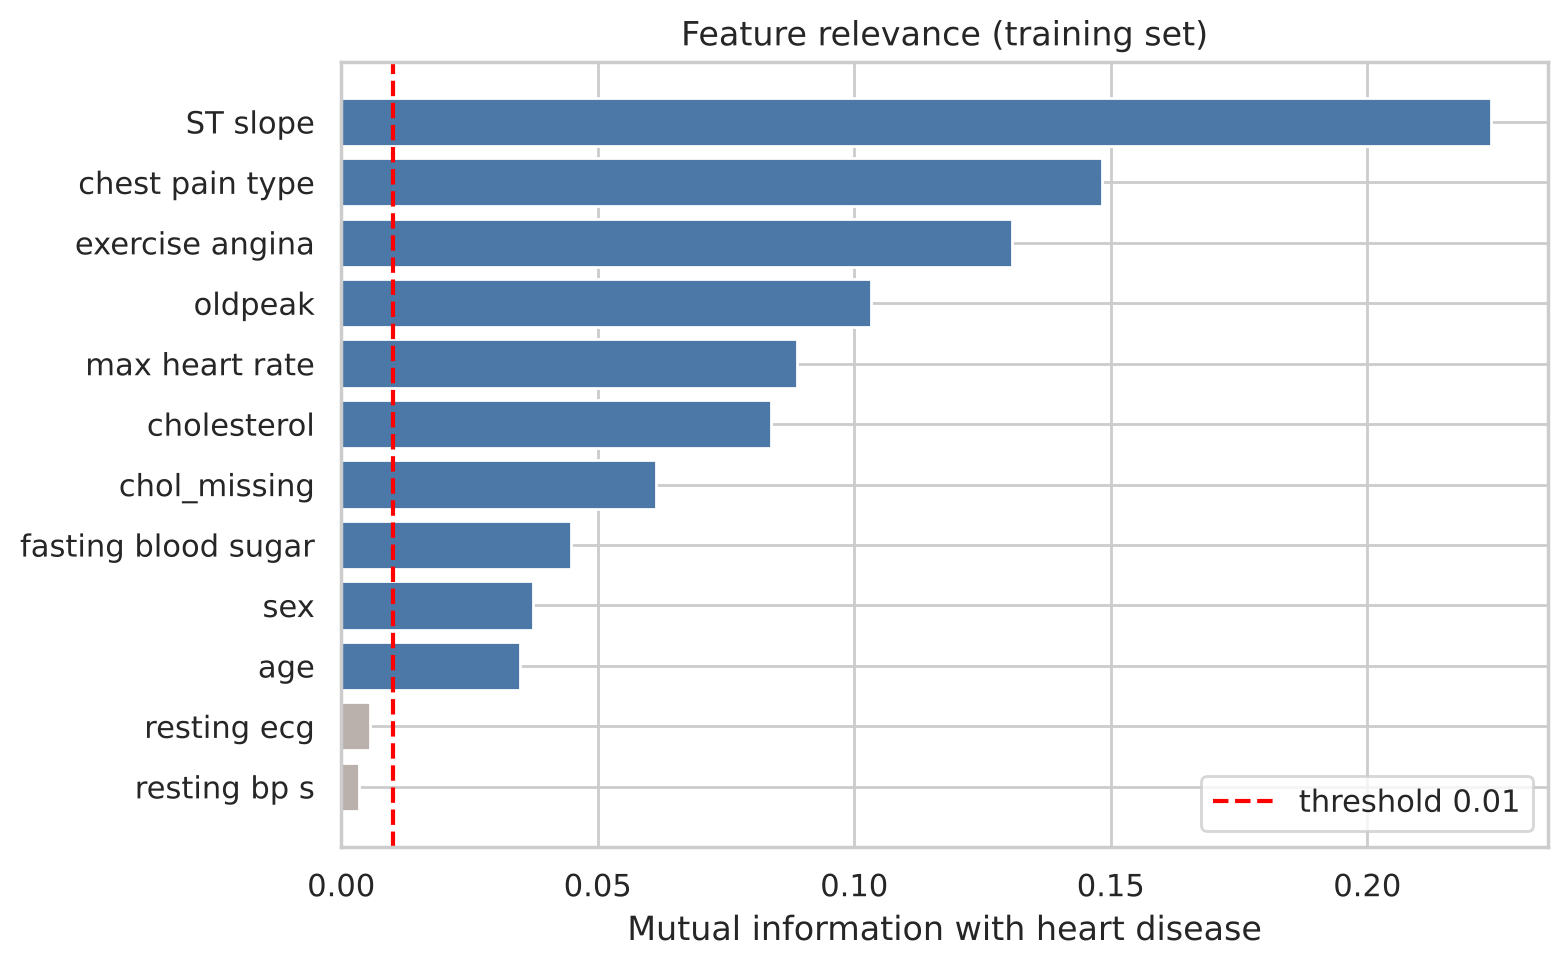

In [21]:
X_codes = X_train.copy()
for c in X_codes.select_dtypes(exclude="number"):
    X_codes[c] = X_codes[c].astype("category").cat.codes
X_codes = X_codes.fillna(X_codes.median())
is_discrete = [c not in numeric_cols for c in X_codes.columns]

mi = pd.Series(mutual_info_classif(X_codes, y_train, discrete_features=is_discrete, random_state=RANDOM_STATE),
               index=X_codes.columns).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(mi.index, mi.values, color=["#BAB0AC" if v < 0.01 else "#4C78A8" for v in mi.values])
plt.axvline(0.01, color="red", linestyle="--", label="threshold 0.01")
plt.xlabel("Mutual information with heart disease")
plt.title("Feature relevance (training set)")
plt.legend()
plt.tight_layout()
plt.show()

## 3.13 Feature selection: does removing weak features help?

- Compare two versions of each model, the first version used all features, second version excluded the weak features
- Weak features (below 0.01) are removed, then every model is cross-validated with and without them
- Same 5-fold split and same model settings, so the only difference is the feature set
- If removing them does not improve accuracy, they are kept (they cost nothing and may help in combination with other features)

In [22]:
weak = mi[mi < 0.01].index.tolist()
print("Weak features:", weak)

check_models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5,
                                             random_state=RANDOM_STATE, n_jobs=-1), False),
    "KNN": (KNeighborsClassifier(n_neighbors=5), True),
}
rows = []
for name, (est, scale) in check_models.items():
    row = {"Model": name}
    for label, drop in [("All features", ()), ("Without weak features", tuple(weak))]:
        pipe = Pipeline([("prep", make_preprocessor(scale, drop)), ("model", est)])
        row[label] = cross_validate(pipe, X_train.drop(columns=list(drop)), y_train, cv=cv,
                                    scoring="accuracy", n_jobs=-1)["test_score"].mean()
    rows.append(row)
selection = pd.DataFrame(rows).set_index("Model")
selection.loc["Average"] = selection.mean()
display(selection.round(4))

winner = "all features" if selection.loc["Average", "All features"] >= selection.loc["Average", "Without weak features"] else "without weak features"
print("Decision: keep", winner)

Weak features: ['resting bp s', 'resting ecg']


,All features,Without weak features
Model,,
Logistic Regression,0.8613,0.8597
Random Forest,0.8645,0.8597
KNN,0.8290,0.8177
Average,0.8516,0.8457


Decision: keep all features


# 4. Training Models

## 4.0 Shared training routine

- Every model uses the **same** training set, the same 5-fold split and the same preprocessing logic
- For each model: 5-fold cross-validation on the training set (accuracy, precision, recall, F1, ROC AUC for both the training and validation parts), then one final fit on the whole training set
- No hyperparameter search: each model gets one fixed, regularized setting

In [23]:
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
models, cv_results = {}, {}

def train_and_validate(name, estimator, scale):
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", estimator)])
    start = time.time()
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING,
                            return_train_score=True, n_jobs=-1)
    pipe.fit(X_train, y_train)
    models[name] = pipe
    cv_results[name] = pd.DataFrame(scores)

    folds = cv_results[name][[f"test_{m}" for m in SCORING]].copy()
    folds.columns = list(SCORING)
    folds.index = [f"Fold {i}" for i in range(1, 6)]
    folds.loc["Mean"] = folds.mean()
    folds.loc["Std"] = folds.iloc[:5].std()
    display(folds.round(4))
    print(f"{name}: training took {time.time() - start:.1f} seconds")

## 4.1 Logistic Regression (linear family)

- **Why chosen:** a simple, fast, interpretable baseline. It is the standard first model for medical risk prediction, and every other model has to beat it to justify its extra complexity
- **What it is best used for:** problems where the classes are roughly separable by a straight boundary, and where you need to explain how each feature pushes the risk up or down (the coefficients)
- **Regularization:** L2 penalty (scikit-learn default) with `C = 1.0`. The penalty shrinks large coefficients to prevent overfitting. No search for `C`
- Needs scaled features, so the scaled pipeline is used

In [24]:
train_and_validate("Logistic Regression",
                   LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
                   scale=True)

,accuracy,precision,recall,f1,roc_auc
Fold 1,0.8710,0.8533,0.9275,0.8889,0.9067
Fold 2,0.8468,0.8676,0.8551,0.8613,0.9328
Fold 3,0.8387,0.8636,0.8382,0.8507,0.9026
Fold 4,0.8468,0.8551,0.8676,0.8613,0.9160
Fold 5,0.9032,0.8889,0.9412,0.9143,0.9512
Mean,0.8613,0.8657,0.8859,0.8753,0.9218
Std,0.0264,0.0142,0.0457,0.0260,0.0201


Logistic Regression: training took 0.2 seconds


## 4.2 Random Forest (tree ensemble family)

- **Why chosen:** it handles mixed feature types, non-linear patterns and feature interactions without any scaling, and it is robust to outliers. It also gives feature importances
- **What it is best used for:** tabular data with non-linear relationships, such as clinical measurements, where it is often the strongest all-round model
- **Regularization:** `max_depth = 5` and `min_samples_leaf = 5` stop the trees from memorizing the training data. 200 trees, each trained on a random sample of patients and features, are averaged to reduce variance
- No scaling needed, so the unscaled pipeline is used

In [25]:
train_and_validate("Random Forest",
                   RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5,
                                          random_state=RANDOM_STATE, n_jobs=-1),
                   scale=False)

,accuracy,precision,recall,f1,roc_auc
Fold 1,0.8548,0.8312,0.9275,0.8767,0.9183
Fold 2,0.8468,0.8378,0.8986,0.8671,0.9299
Fold 3,0.8548,0.8676,0.8676,0.8676,0.9036
Fold 4,0.8871,0.8750,0.9265,0.9000,0.9265
Fold 5,0.8790,0.8630,0.9265,0.8936,0.9522
Mean,0.8645,0.8549,0.9093,0.8810,0.9261
Std,0.0175,0.0193,0.0263,0.0151,0.0178


Random Forest: training took 1.7 seconds


## 4.3 K-Nearest Neighbors (instance-based family)

- **Why chosen:** a different way of learning. It stores the training patients and classifies a new patient by a vote of the 5 most similar ones. It is easy to explain and makes no assumption about the shape of the data
- **What it is best used for:** small datasets where similar cases tend to have the same outcome and where local patterns matter more than one global rule
- **Regularization:** `n_neighbors = 5`, the default. More neighbors give a smoother, less overfit boundary. No search for `k`
- Distance based, so scaling is essential (otherwise cholesterol in the hundreds would drown out oldpeak between 0 and 6)

In [26]:
train_and_validate("KNN", KNeighborsClassifier(n_neighbors=5), scale=True)

,accuracy,precision,recall,f1,roc_auc
Fold 1,0.8306,0.8077,0.9130,0.8571,0.8974
Fold 2,0.8065,0.8169,0.8406,0.8286,0.8883
Fold 3,0.8468,0.8551,0.8676,0.8613,0.8915
Fold 4,0.8145,0.8261,0.8382,0.8321,0.8670
Fold 5,0.8468,0.8267,0.9118,0.8671,0.8968
Mean,0.8290,0.8265,0.8743,0.8493,0.8882
Std,0.0184,0.0178,0.0367,0.0177,0.0124


KNN: training took 0.2 seconds


# 5. Visualization of Results

## 5.1 Predictions and test metrics

- Each trained model predicts the 266 test patients (and the training patients, for the overfitting check later)
- Metrics on the test set: accuracy, precision, recall, F1 and ROC AUC for the disease class

Metrics meaning:
- Accuracy: The percentage of all patients the model got right
- - How often is the model right?
- Precision: The percentage of patients predicted sick that were actually sick (high precision = less false positive)
- - Can I trust a sick prediction?
- Recall: The percentage of patients who were sick and the model actually caught (high recall = less false negatives)
- - Did we find all the sick people?
- F1: A single score that balances Precision and Recall
- - Is the model good at trusting sick predictions and finding all the sick people?
- ROC AUC: How well a model ranks sick patients above healthy ones (from 0.5 = guessing to 1 = perfect)
- - Can the model tell the sick and healthy people apart, whatever cutoff we use?

In [27]:
preds, rows = {}, []
for name, pipe in models.items():
    preds[name] = {
        "test_pred": pipe.predict(X_test), "test_proba": pipe.predict_proba(X_test)[:, 1],
        "train_pred": pipe.predict(X_train), "train_proba": pipe.predict_proba(X_train)[:, 1],
    }
    p = preds[name]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p["test_pred"]),
                 "Precision": precision_score(y_test, p["test_pred"]),
                 "Recall": recall_score(y_test, p["test_pred"]),
                 "F1": f1_score(y_test, p["test_pred"]),
                 "ROC AUC": roc_auc_score(y_test, p["test_proba"])})
results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.8759,0.8750,0.9048,0.8896,0.9255
Random Forest,0.9098,0.8917,0.9524,0.9211,0.9495
KNN,0.8759,0.8654,0.9184,0.8911,0.9128


## 5.2 Confusion matrices

- Rows are the true class, columns the predicted class
- Bottom-left cell = **false negatives** (sick patients predicted healthy), the most dangerous error
- Top-right cell = false positives (healthy patients flagged for extra tests)

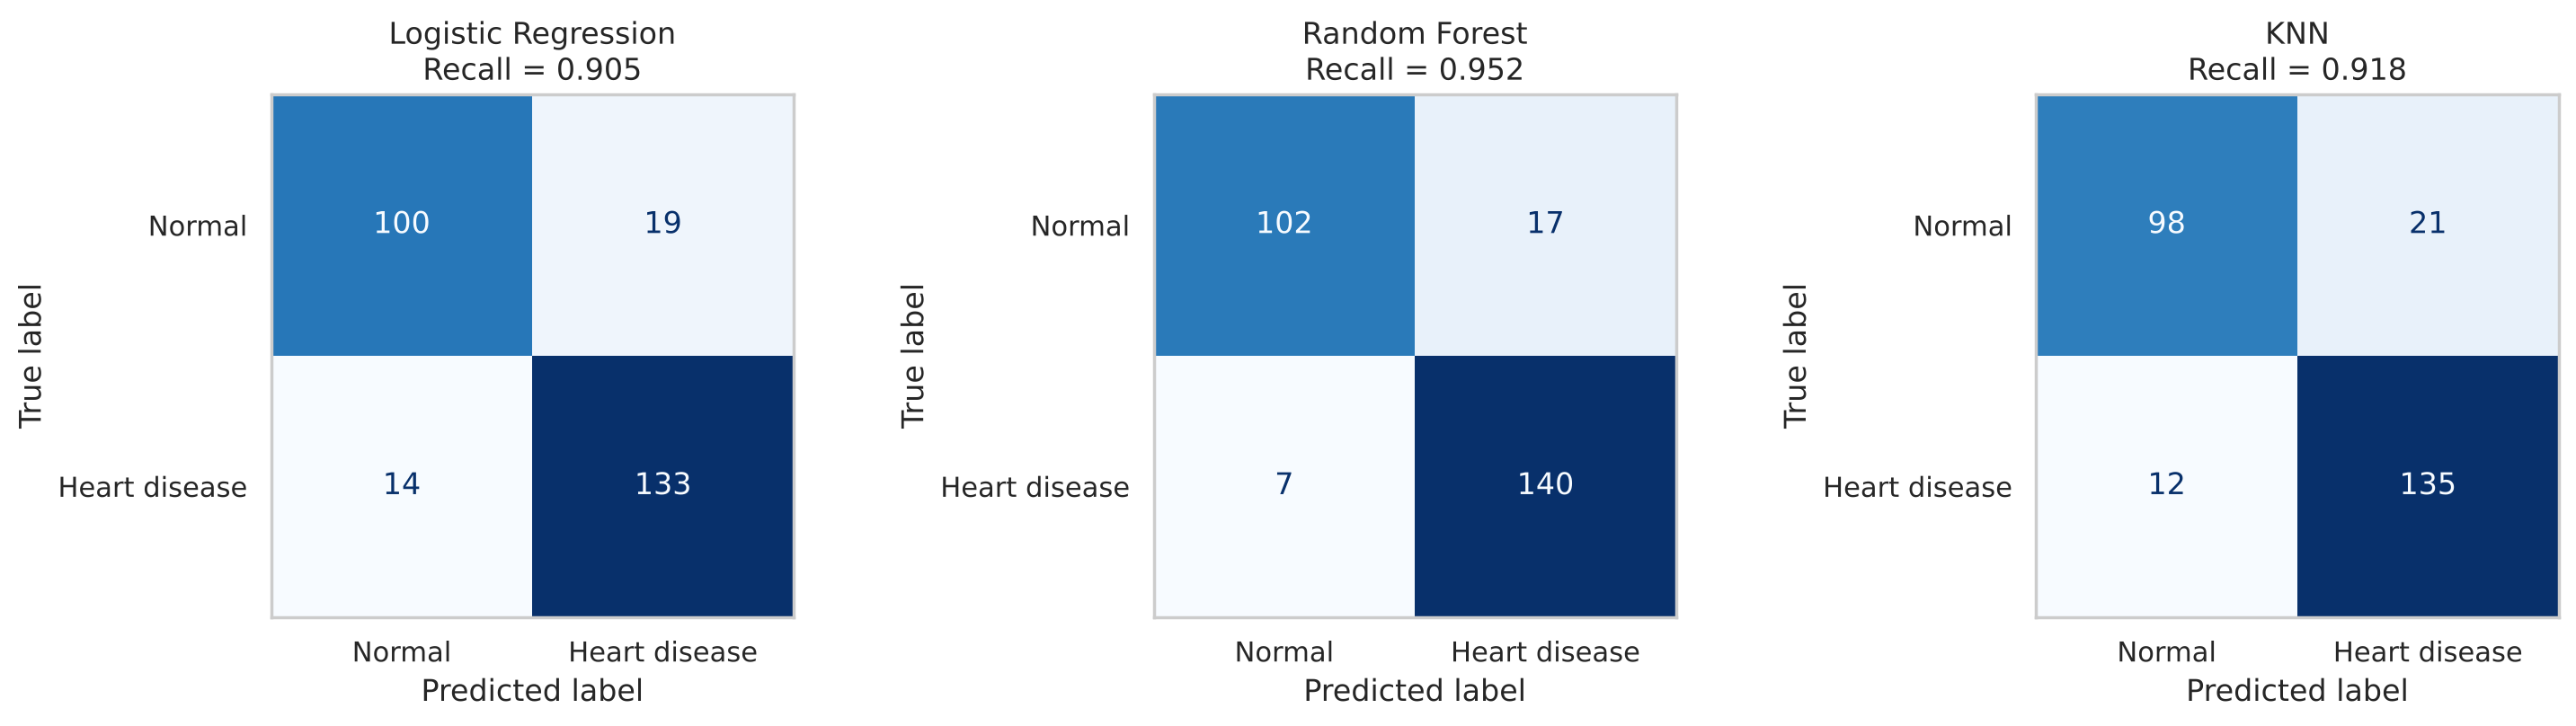

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name]["test_pred"], display_labels=CLASS_NAMES,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nRecall = {results.loc[name, 'Recall']:.3f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

## 5.3 Classification reports

- Precision, recall and F1 for each class separately, plus the overall averages

In [29]:
for name in models:
    print("=" * 60)
    print(name)
    print(classification_report(y_test, preds[name]["test_pred"], target_names=CLASS_NAMES, digits=3))

Logistic Regression
               precision    recall  f1-score   support

       Normal      0.877     0.840     0.858       119
Heart disease      0.875     0.905     0.890       147

     accuracy                          0.876       266
    macro avg      0.876     0.873     0.874       266
 weighted avg      0.876     0.876     0.876       266

Random Forest
               precision    recall  f1-score   support

       Normal      0.936     0.857     0.895       119
Heart disease      0.892     0.952     0.921       147

     accuracy                          0.910       266
    macro avg      0.914     0.905     0.908       266
 weighted avg      0.911     0.910     0.909       266

KNN
               precision    recall  f1-score   support

       Normal      0.891     0.824     0.856       119
Heart disease      0.865     0.918     0.891       147

     accuracy                          0.876       266
    macro avg      0.878     0.871     0.873       266
 weighted avg      

## 5.4 ROC curves: training vs test (overfitting check)

- The ROC curve shows the true positive rate against the false positive rate at every possible threshold. The diagonal is random guessing, and the closer to the top-left corner the better
- One panel per model, with the training curve (dashed) and the test curve (solid)
- If the training AUC is far above the test AUC, the model memorized the training data

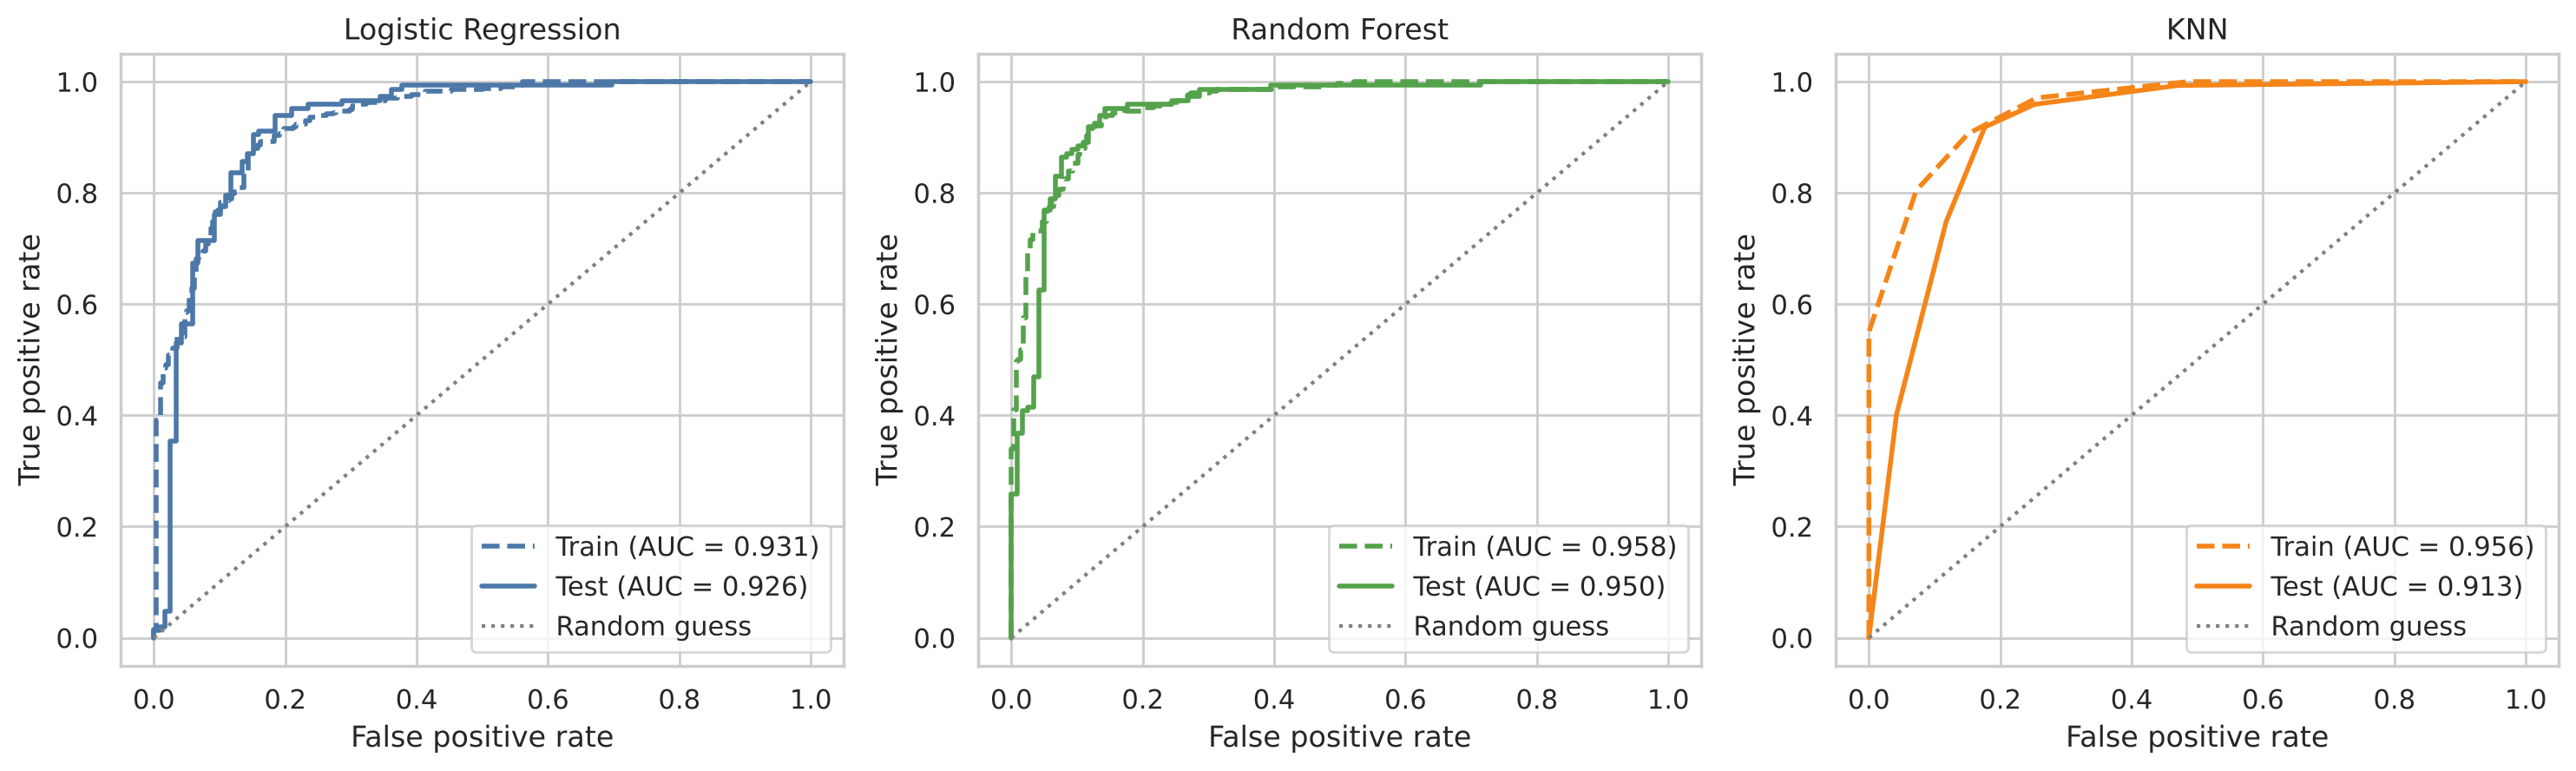

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name in zip(axes, models):
    for split, y_true, proba, style in [("Train", y_train, preds[name]["train_proba"], "--"),
                                        ("Test", y_test, preds[name]["test_proba"], "-")]:
        fpr, tpr, _ = roc_curve(y_true, proba)
        ax.plot(fpr, tpr, style, color=MODEL_COLORS[name], linewidth=2,
                label=f"{split} (AUC = {roc_auc_score(y_true, proba):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Random guess")
    ax.set_title(name)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5.5 Overfitting check: training vs cross-validation vs test

- Accuracy and ROC AUC on the training set, in cross-validation and on the test set
- A big gap between training and the other two means overfitting. Cross-validation and test agreeing means the result can be trusted
- - Use **CV** score to validate **Test** score and compare the **Test** score to **Train** score to see if the model learned

,Train accuracy,CV accuracy,Test accuracy,Train AUC,CV AUC,Test AUC,Gap accuracy (train - test),Gap AUC (train - test)
Model,,,,,,,,
Logistic Regression,0.8629,0.8613,0.8759,0.9307,0.9218,0.9255,-0.0130,0.0052
Random Forest,0.8968,0.8645,0.9098,0.9578,0.9261,0.9495,-0.0130,0.0083
KNN,0.8806,0.8290,0.8759,0.9555,0.8882,0.9128,0.0047,0.0427


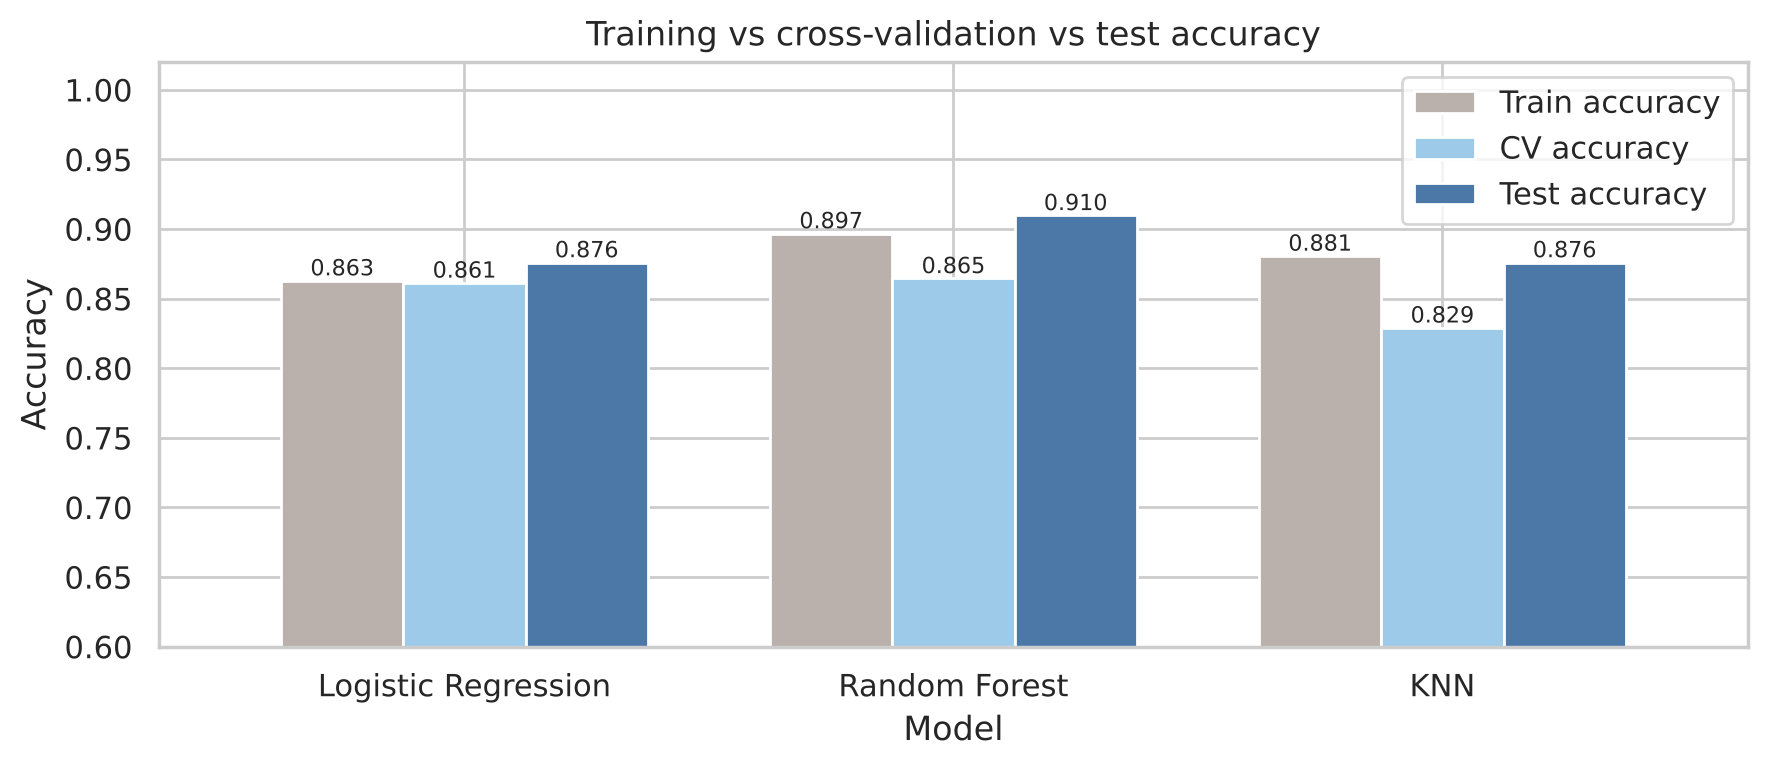

In [31]:
rows = []
for name in models:
    p, cvr = preds[name], cv_results[name]
    rows.append({"Model": name,
                 "Train accuracy": accuracy_score(y_train, p["train_pred"]),
                 "CV accuracy": cvr["test_accuracy"].mean(),
                 "Test accuracy": accuracy_score(y_test, p["test_pred"]),
                 "Train AUC": roc_auc_score(y_train, p["train_proba"]),
                 "CV AUC": cvr["test_roc_auc"].mean(),
                 "Test AUC": roc_auc_score(y_test, p["test_proba"])})
overfit = pd.DataFrame(rows).set_index("Model")
overfit["Gap accuracy (train - test)"] = overfit["Train accuracy"] - overfit["Test accuracy"]
overfit["Gap AUC (train - test)"] = overfit["Train AUC"] - overfit["Test AUC"]
display(overfit.round(4))

ax = overfit[["Train accuracy", "CV accuracy", "Test accuracy"]].plot(
    kind="bar", figsize=(9, 4), color=["#BAB0AC", "#9ECAE9", "#4C78A8"], width=0.75)
ax.set_ylim(0.6, 1.02)
ax.set_ylabel("Accuracy")
ax.set_title("Training vs cross-validation vs test accuracy")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

## 5.6 Most predictive features

- **Logistic Regression:** coefficients on scaled features (positive = raises disease risk, negative = lowers it)
- **Random Forest:** importance = how much each feature reduces impurity across all trees
- KNN has no coefficients or importances, so it is not shown

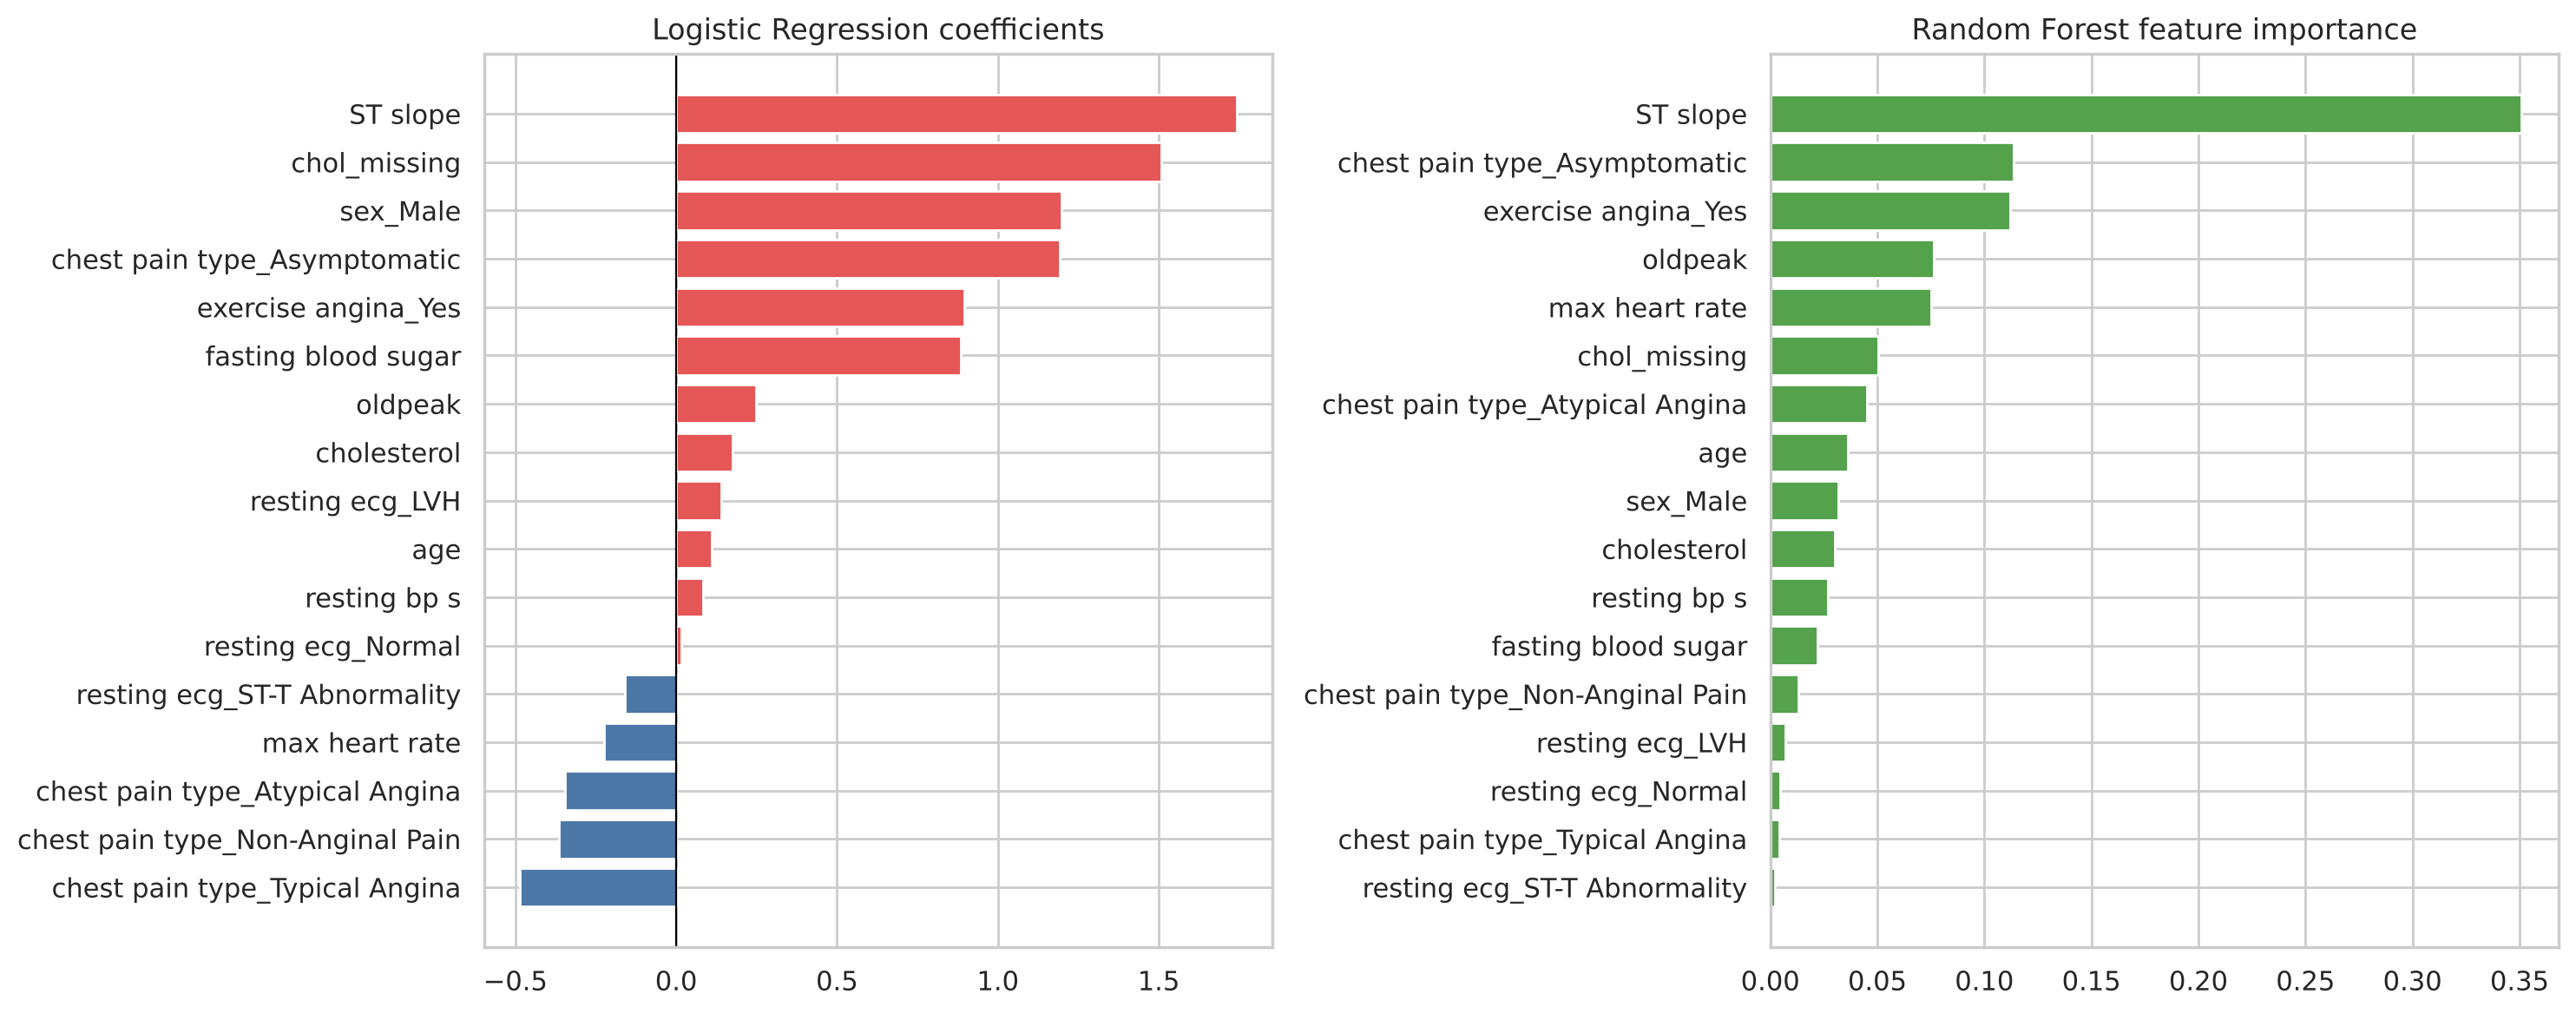

In [32]:
def feature_names(pipe):
    return [n.split("__", 1)[1] for n in pipe["prep"].get_feature_names_out()]

lr = models["Logistic Regression"]
coef = pd.Series(lr["model"].coef_[0], index=feature_names(lr)).sort_values()
rf = models["Random Forest"]
imp = pd.Series(rf["model"].feature_importances_, index=feature_names(rf)).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(coef.index, coef.values, color=["#E45756" if v > 0 else "#4C78A8" for v in coef.values])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Logistic Regression coefficients")
axes[1].barh(imp.index, imp.values, color=MODEL_COLORS["Random Forest"])
axes[1].set_title("Random Forest feature importance")
plt.tight_layout()
plt.show()

### Same two charts, but both models use the same feature order (Random Forest ranking)

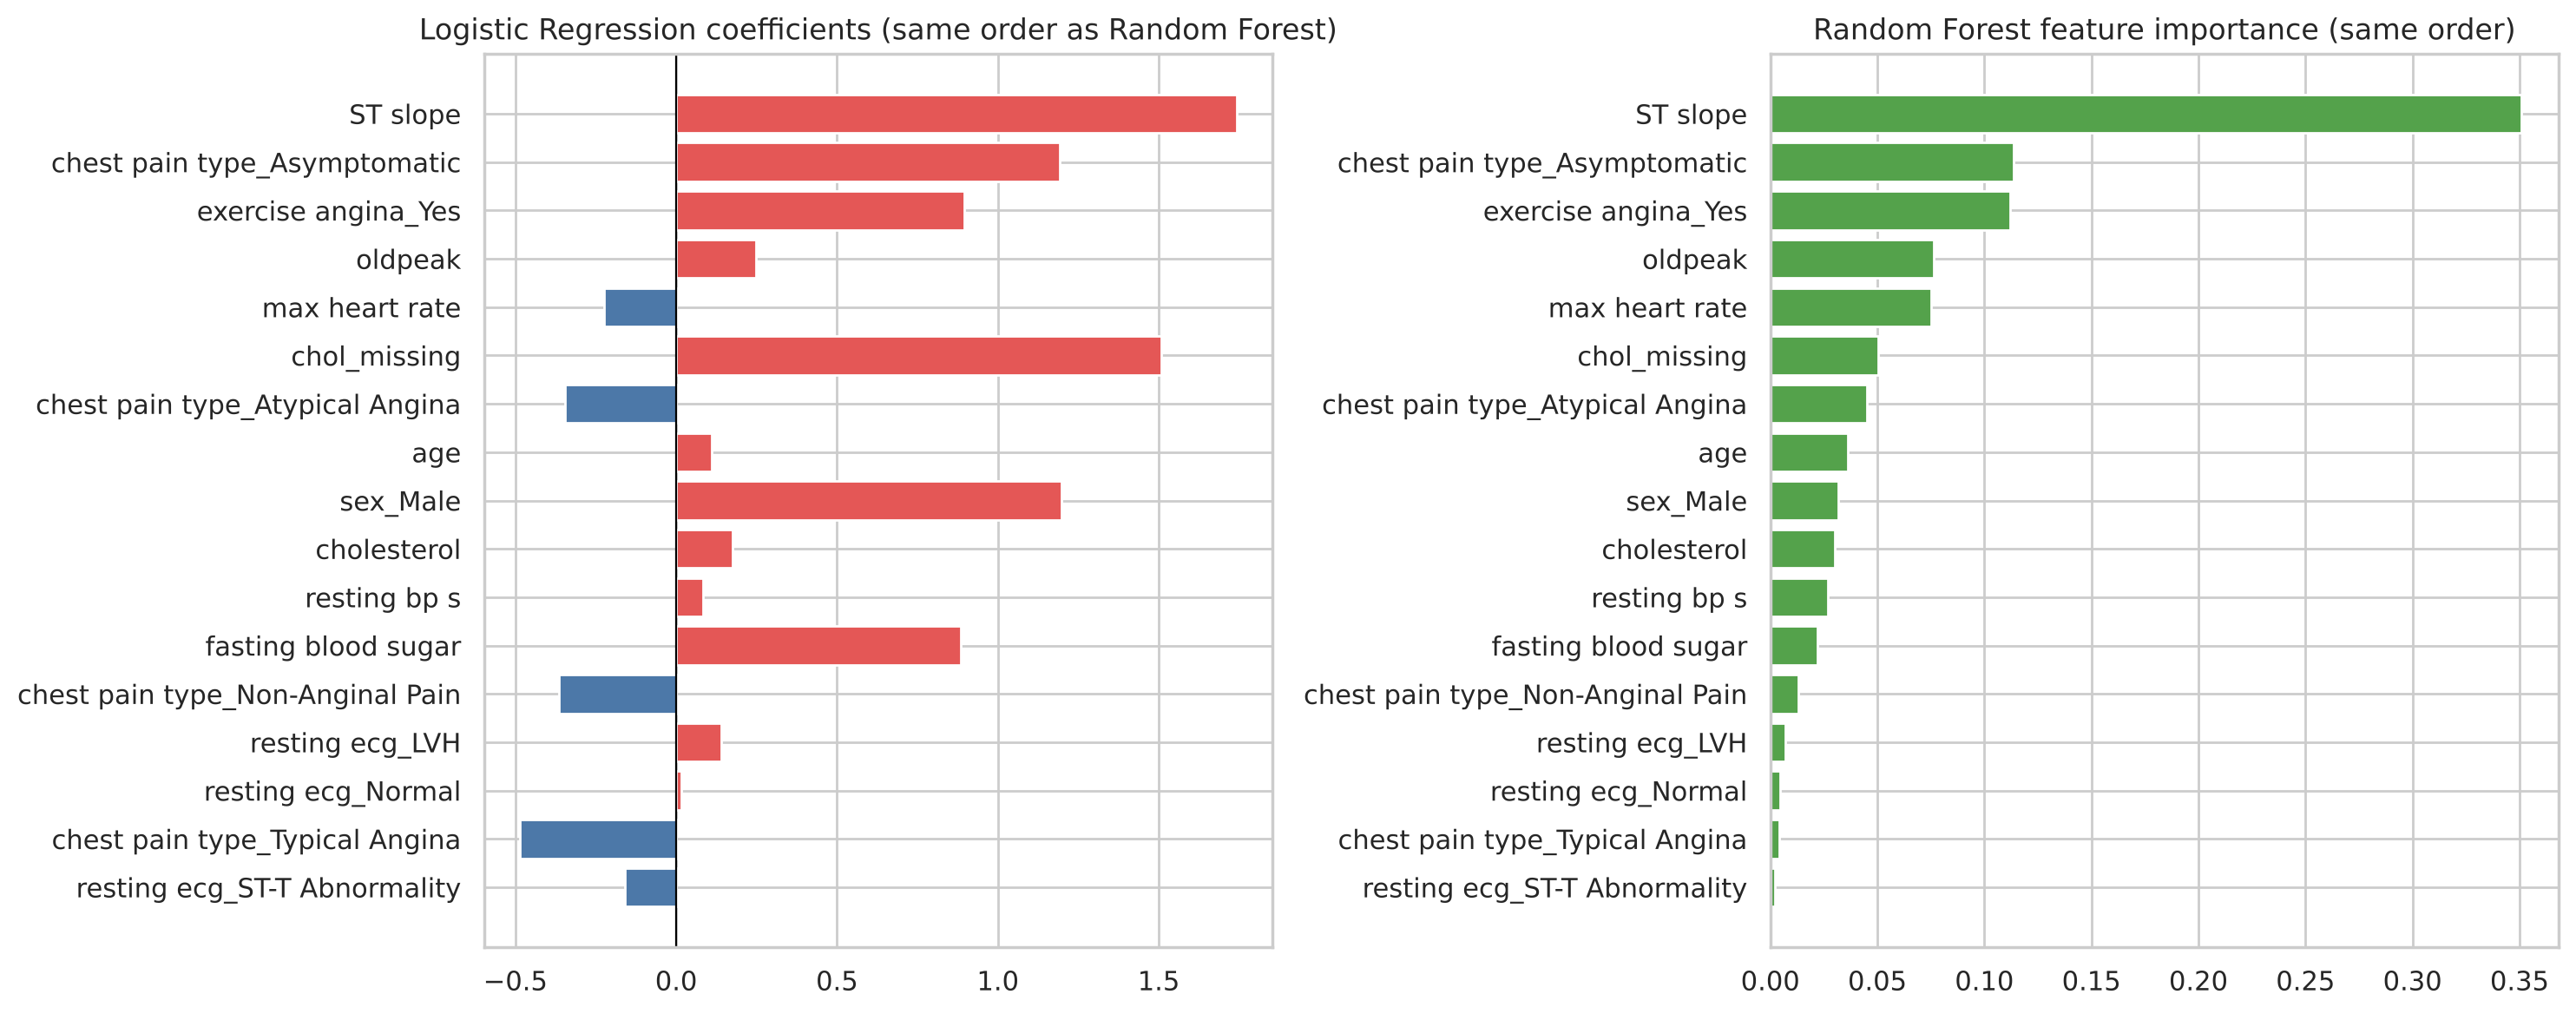

In [33]:
same_order = imp.index
coef_same = coef.reindex(same_order)
imp_same = imp.reindex(same_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(coef_same.index, coef_same.values, color=["#E45756" if v > 0 else "#4C78A8" for v in coef_same.values])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Logistic Regression coefficients (same order as Random Forest)")
axes[1].barh(imp_same.index, imp_same.values, color=MODEL_COLORS["Random Forest"])
axes[1].set_title("Random Forest feature importance (same order)")
plt.tight_layout()
plt.show()

# 6. Comparison of All Models Together

## 6.1 Summary table

- One table with cross-validation and test results for all three models, sorted by F1
- Cross-validation columns come from the training set only, test columns from the 266 unseen patients

In [34]:
summary = pd.DataFrame({
    "CV accuracy": {n: cv_results[n]["test_accuracy"].mean() for n in models},
    "CV accuracy std": {n: cv_results[n]["test_accuracy"].std() for n in models},
    "Test accuracy": results["Accuracy"],
    "Test precision": results["Precision"],
    "Test recall": results["Recall"],
    "Test F1": results["F1"],
    "Test ROC AUC": results["ROC AUC"],
    "Train-test accuracy gap": overfit["Gap accuracy (train - test)"],
}).sort_values("Test F1", ascending=False)
display(summary.round(4))

,CV accuracy,CV accuracy std,Test accuracy,Test precision,Test recall,Test F1,Test ROC AUC,Train-test accuracy gap
Random Forest,0.8645,0.0175,0.9098,0.8917,0.9524,0.9211,0.9495,-0.0130
KNN,0.8290,0.0184,0.8759,0.8654,0.9184,0.8911,0.9128,0.0047
Logistic Regression,0.8613,0.0264,0.8759,0.8750,0.9048,0.8896,0.9255,-0.0130


## 6.2 Metric comparison chart

- Test accuracy, precision, recall, F1 and ROC AUC side by side for every model

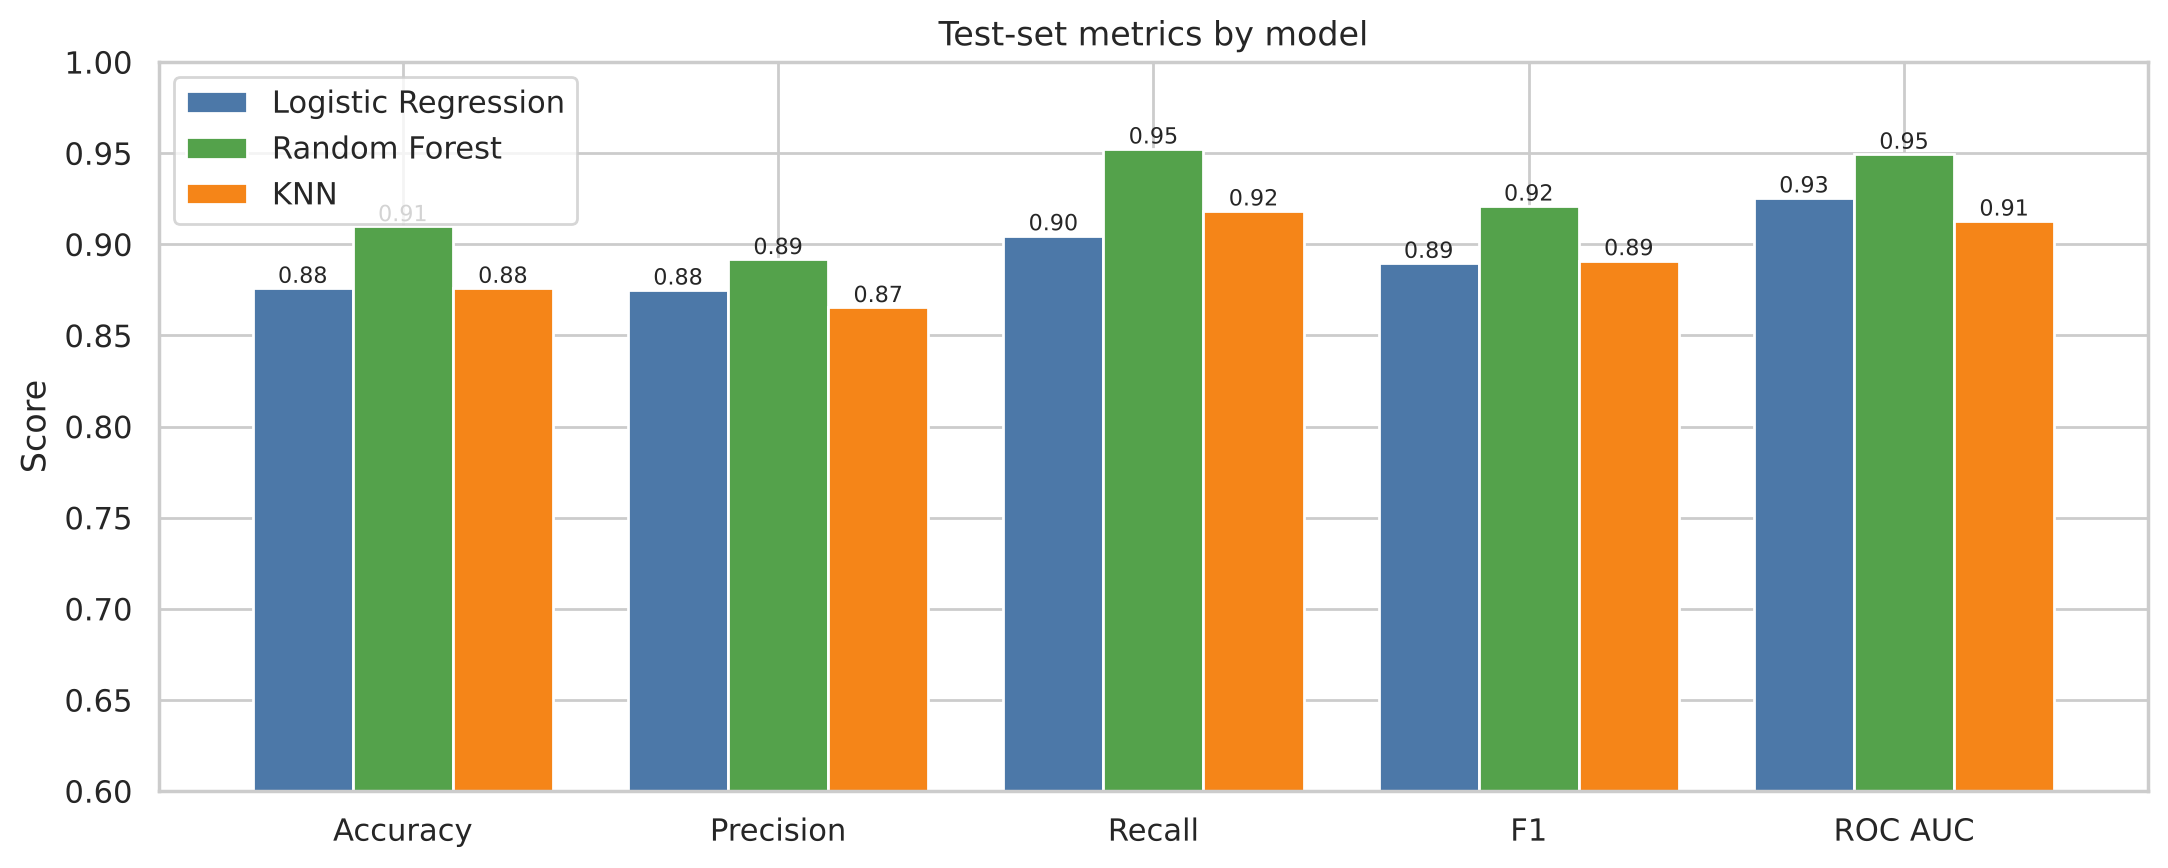

In [35]:
ax = results.T.plot(kind="bar", figsize=(11, 4.5), color=[MODEL_COLORS[m] for m in results.index], width=0.8)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Score")
ax.set_title("Test-set metrics by model")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.legend(title="")
plt.tight_layout()
plt.show()

## 6.3 ROC curves: all models on one plot

- Test-set ROC curves of the three models together, with the AUC in the legend
- The curve that sits highest and furthest into the top-left corner is the best at ranking sick patients above healthy ones

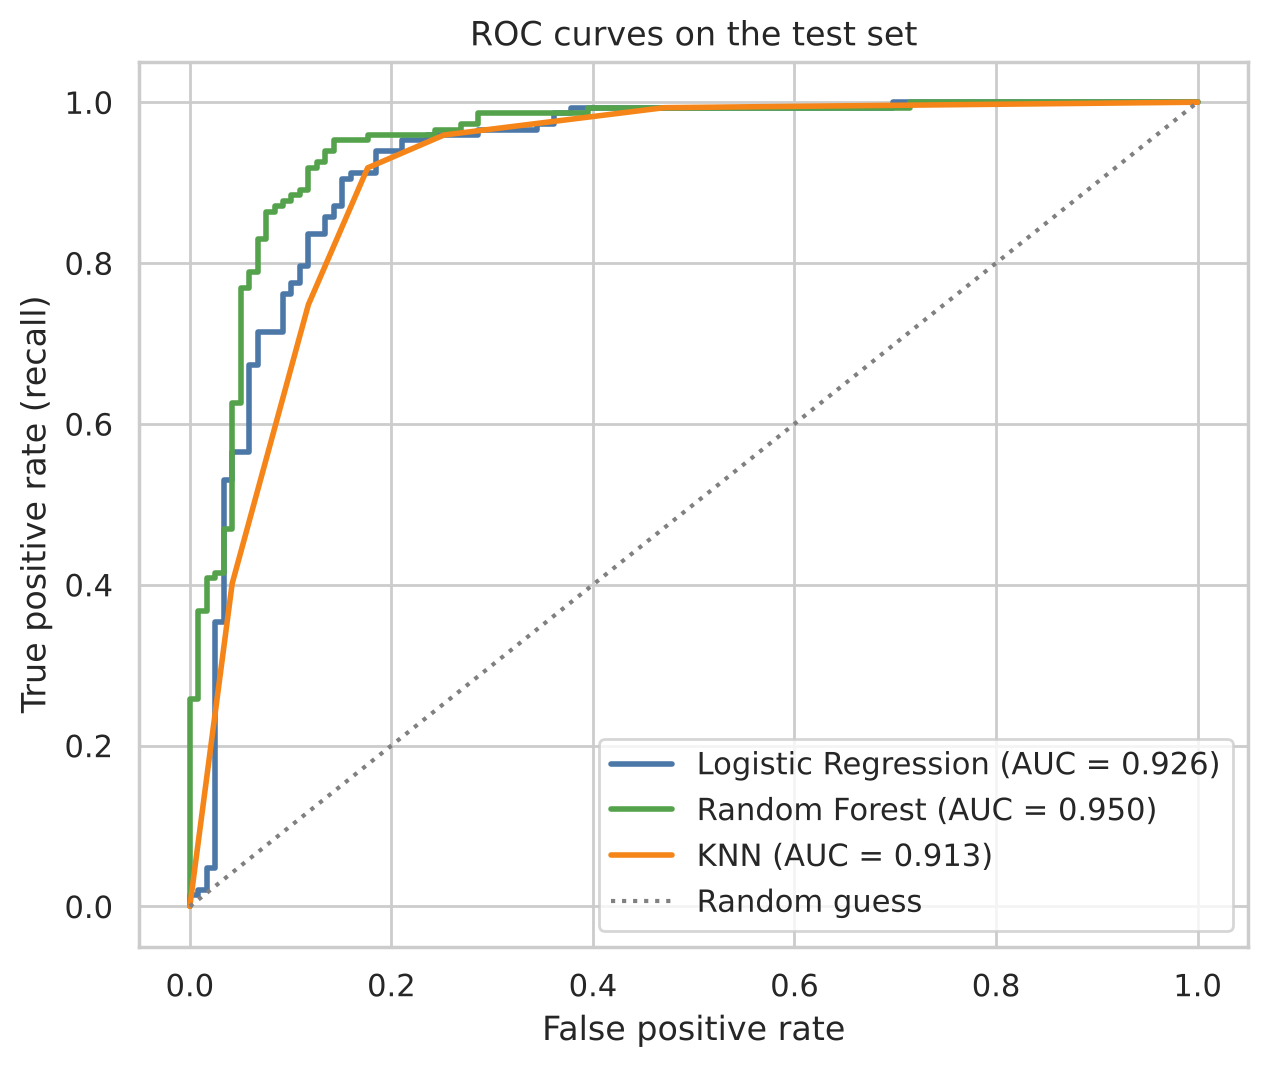

In [36]:
plt.figure(figsize=(6.5, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, preds[name]["test_proba"])
    plt.plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=2,
             label=f"{name} (AUC = {results.loc[name, 'ROC AUC']:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6.4 Histogram of predicted probabilities

- For each model, the distribution of the predicted probability of heart disease on the test set, split by the true class
- A good model pushes sick patients to the right and healthy patients to the left, with little overlap
- The dashed line at 0.5 is the decision threshold used for the predictions above
- Anyone sick on the left is a missed patient (false negative)
- Anyone healthy on the right is a false alarm (false positive)

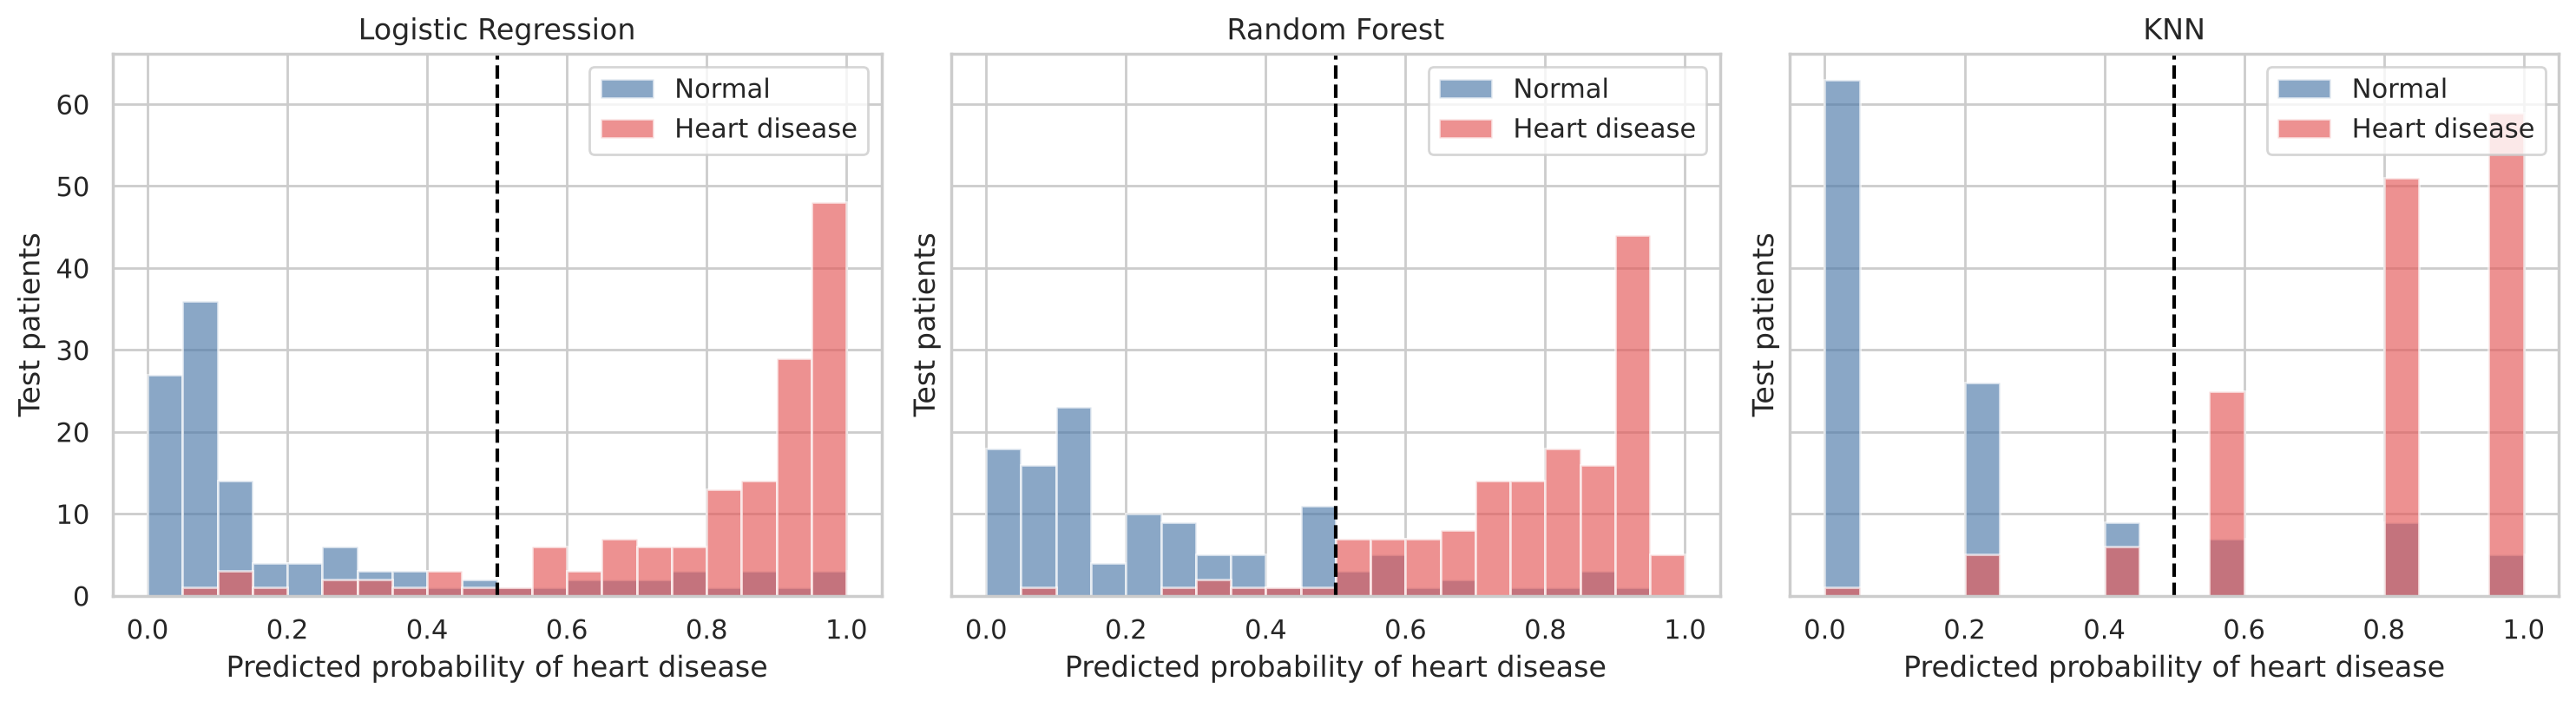

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, name in zip(axes, models):
    for cls, label in [(0, "Normal"), (1, "Heart disease")]:
        ax.hist(preds[name]["test_proba"][y_test.values == cls], bins=20, range=(0, 1),
                alpha=0.65, color=CLASS_COLORS[cls], label=label)
    ax.axvline(0.5, color="black", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted probability of heart disease")
    ax.set_ylabel("Test patients")
    ax.legend()
plt.tight_layout()
plt.show()

## 6.5 Stability across cross-validation folds

- F1 score of each model on each of the 5 validation folds
- A narrow box means the model gives consistent results whichever patients it trains on
- Black dots = F1 score for 1 of the folds
- Open circle = a fold flagged as an outlier (far from the other folds)

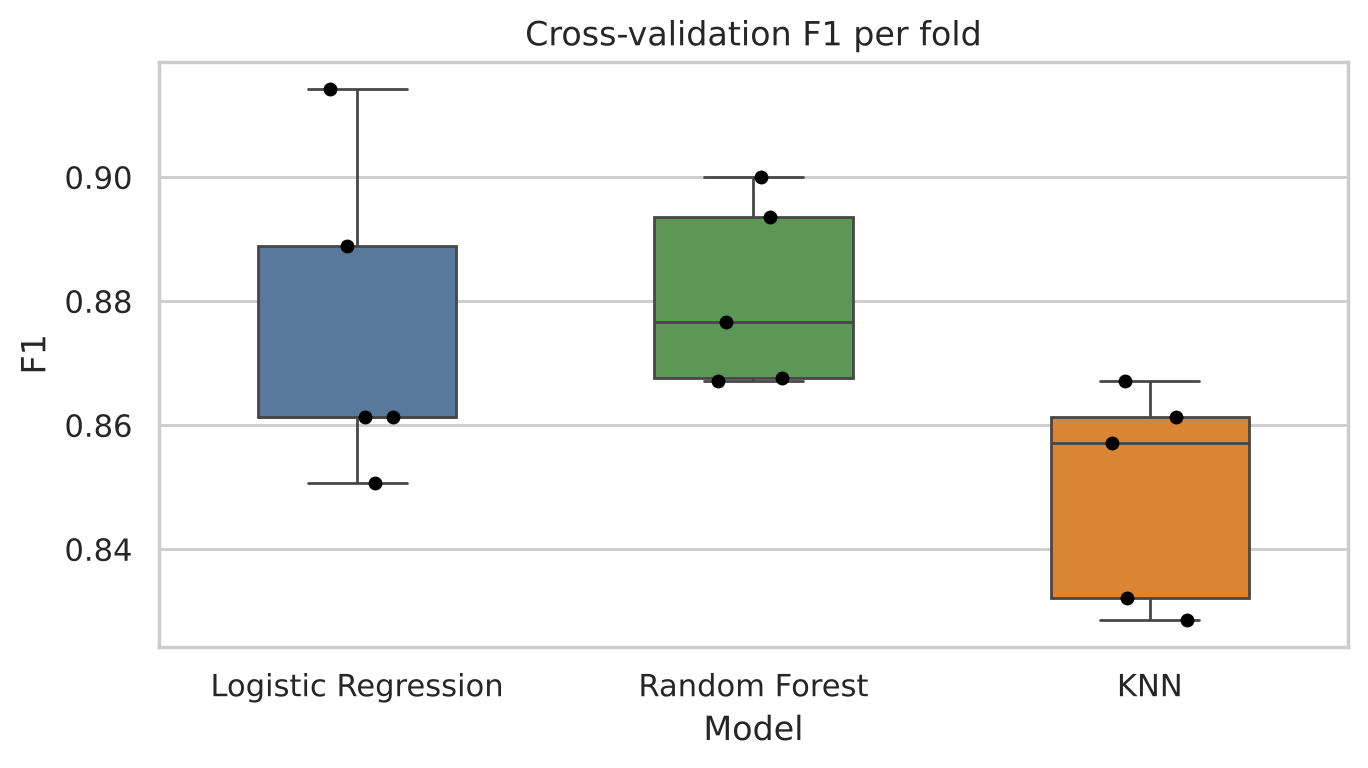

In [38]:
fold_f1 = pd.DataFrame({n: cv_results[n]["test_f1"] for n in models}).melt(var_name="Model", value_name="F1")
plt.figure(figsize=(7, 4))
sns.boxplot(data=fold_f1, x="Model", y="F1", hue="Model", palette=MODEL_COLORS, width=0.5, dodge=False, legend=False)
sns.stripplot(data=fold_f1, x="Model", y="F1", color="black", size=5)
plt.title("Cross-validation F1 per fold")
plt.tight_layout()
plt.show()

## 6.6 Ranking and best model

- Models ranked by F1 (balance of precision and recall) and by recall (fewest missed sick patients)

In [39]:
print("Ranking by test F1:    ", " > ".join(results["F1"].sort_values(ascending=False).index))
print("Ranking by test recall:", " > ".join(results["Recall"].sort_values(ascending=False).index))
print("Ranking by test AUC:   ", " > ".join(results["ROC AUC"].sort_values(ascending=False).index))
best = results["F1"].idxmax()
print(f"\nBest overall model (highest test F1): {best}")
print(f"False negatives on the test set (sick patients missed):")
for name in models:
    fn = int(((y_test.values == 1) & (preds[name]["test_pred"] == 0)).sum())
    print(f"  {name}: {fn} of {int((y_test == 1).sum())}")

Ranking by test F1:     Random Forest > KNN > Logistic Regression
Ranking by test recall: Random Forest > KNN > Logistic Regression
Ranking by test AUC:    Random Forest > Logistic Regression > KNN

Best overall model (highest test F1): Random Forest
False negatives on the test set (sick patients missed):
  Logistic Regression: 14 of 147
  Random Forest: 7 of 147
  KNN: 12 of 147


## 6.7 Discussion

**Results on the 266 unseen test patients (same as 6.1 table)**

| Model | Accuracy | Precision | Recall | F1 | ROC AUC | CV accuracy | Sick patients missed |
|---|---|---|---|---|---|---|---|
| Random Forest | 91.0% | 89.2% | 95.2% | 92.1% | 0.950 | 86.5% | 7 of 147 |
| Logistic Regression | 87.6% | 87.5% | 90.5% | 89.0% | 0.926 | 86.1% | 14 of 147 |
| KNN | 87.6% | 86.5% | 91.8% | 89.1% | 0.913 | 82.9% | 12 of 147 |

**Best model: Random Forest**
- It ranks first on every test metric (accuracy, precision, recall, F1, AUC) and in cross-validation, and it misses the fewest sick patients (7 of 147), which is the error that matters most here
- **Why it wins:** it captures non-linear patterns and interactions between features (for example `ST slope` together with exercise angina and oldpeak), handles the mixed feature types and the `chol_missing` flag naturally, and averaging 200 depth-limited trees reduces variance
- **Logistic Regression and KNN tie for second on the test set:** same accuracy (87.6%), and KNN's F1 is higher by only 0.1 point. Logistic Regression is the stronger of the two overall: higher AUC (0.926 vs 0.913) and clearly higher cross-validation accuracy (86.1% vs 82.9%). Many relationships here are close to linear, so a simple, fully interpretable model does well
- **Why KNN is weakest in cross-validation:** distances over 17 mixed features (many of them one-hot columns) are a crude measure of patient similarity, and with 5 neighbors its probabilities are coarse (visible in the histogram: only 6 possible values)
- **Be careful with the gap:** Random Forest beats Logistic Regression by about 9 patients out of 266 on the test set, but in cross-validation the two are almost equal (86.5% vs 86.1%) and the fold-to-fold spread is 2 to 3 points, so part of the test lead is luck of the split
- **Test scores are higher than cross-validation for all three models** (for example Random Forest 91.0% vs 86.5%): this test split happens to be slightly easier, so the cross-validation score (about 86%) is the more conservative estimate for new patients

**Overfitting check**
- **Logistic Regression:** training 86.3%, CV 86.1% and test 87.6% are all close, and the AUC gap is 0.005, so no overfitting
- **Random Forest:** training accuracy 89.7% vs CV 86.5%, a mild gap. The train vs test AUC gap is only 0.008, and the depth limit kept the trees under control
- **KNN:** the largest AUC gap (train 0.956 vs test 0.913) and the largest drop from training to CV accuracy (88.1% vs 82.9%), so it overfits the most. KNN always scores very well on patients it has stored, which makes its training scores optimistic
- The train vs test ROC curves show the same story

**Most predictive features**
- Both Random Forest importances and Logistic Regression coefficients point to `ST slope`, asymptomatic chest pain, exercise angina, oldpeak, max heart rate and the `chol_missing` flag. Male sex and fasting blood sugar get large Logistic Regression weights but are used little by Random Forest
- Cholesterol value, resting blood pressure and resting ECG add very little. Removing the weakest two (resting blood pressure and resting ECG) did not improve cross-validated accuracy (85.2% with all features vs 84.6% without), so they were kept

**Limitations and challenges**
- **Small dataset:** 886 unique patients, and one test patient is 0.38% of the score. Results from a single split carry some luck
- **Duplicates in the source file:** 114 patients were recorded twice under different IDs. They were removed so no patient can appear in both the training and the test set
- **No hyperparameter tuning (by instruction):** each model used one fixed regularized setting, so none is fully optimized and the ranking could change after tuning
- **`chol_missing` is a data-collection signal, not a medical cause:** it is very predictive here, but it may reflect how patients were recorded and might not hold for patients from another hospital
- **Imputation:** 172 cholesterol values were filled with the median, so the cholesterol column carries little real information for those patients
- **Threshold:** predictions use the default 0.5 cutoff. For screening, a lower cutoff would catch more sick patients at the cost of more false alarms (the ROC curve shows this trade-off)
- **No external validation:** the models were not checked on data from a different source

**Possible improvements**
- Tune the hyperparameters with cross-validation (`C`, `max_depth`, `n_neighbors`)
- Choose the decision threshold to reach a target recall
- Get real cholesterol measurements for the patients with missing values